# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo 19:**

* **Nombre y matrícula:** Jorge Hernández Montero, A01733616
* **Nombre y matrícula:** Carla Estefanía Hidalgo Horta, A01018380
* **Nombre y matrícula:** Carlos Manuel Hernández Gutiérrez, A00812506
* **Nombre y matrícula:** Karla Berenice Hernández Centeno, A01797382

In [1]:
# Incluyan todas las celdas de código y texto que requieran.
import sys, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, xgboost
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, KFold, GridSearchCV, RandomizedSearchCV,
                                     cross_validate, cross_val_predict, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler,
                                   PowerTransformer, FunctionTransformer)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error)
from xgboost import XGBRegressor

RANDOM_STATE = 11      # semilla única para particiones, validación cruzada y modelos
ANIO_ACTUAL = 2026     # año de referencia que fija la consigna para las edades
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
# Aviso esperado: en validación cruzada aparecen categorías que el pliegue de entrenamiento no vio, y
# OneHotEncoder(handle_unknown='ignore') las codifica como ceros, sin asignarlas a ninguna categoría conocida.
# Es el comportamiento buscado, así que el aviso se silencia de forma explícita.
warnings.filterwarnings('ignore', category=UserWarning, message='Found unknown categories')
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.17 | scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 3.0.5 | numpy 2.5.3


## **Cómo está organizado el cuaderno**

| Parte | Contenido |
| --- | --- |
| Preparación de los datos | Carga, revisión de calidad, partición, alcance del modelo, reglas del diccionario de datos y exploración en entrenamiento |
| Incisos 1 a 7 | Restricciones temporales, procesamiento y partición, cada uno con su evidencia |
| Incisos 8 y 9 | Modelo base y los seis tipos de modelo, con curvas de aprendizaje y tabla de métricas de validación cruzada |
| Incisos 10 a 15 | Factores del mejor modelo, selección de los tres mejores y ensambles |
| Evaluación final en prueba | La única consulta a la prueba, su incertidumbre, el análisis de errores y la verificación del pipeline desplegable |
| Inciso 16 | Reportes para el equipo técnico y para el director |
| Conclusiones | Inciso 17 |

Los datos son el archivo `train.csv` del reto de Kaggle, 1,460 casas de Ames, Iowa, vendidas entre 2006 y 2010. El `test.csv` de Kaggle no trae `SalePrice`, así que no sirve para evaluar. Para correr el cuaderno, `train.csv` (de https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data, SHA-256 `1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41`) debe estar en la misma carpeta. No se incluye en el repositorio porque las reglas de Kaggle restringen su redistribución. La ejecución completa tarda unos 15 minutos con 2 núcleos, y la primera celda imprime las versiones de las bibliotecas.

**Resultado.** El mejor modelo es una máquina de vector soporte con kernel radial (SVR), con un RMSE de 18,890 USD en validación cruzada y de 19,654 USD en prueba (20,060 USD con el protocolo de uso, que fija una venta normal), contra 72,450 USD del modelo base en prueba. Ningún ensamble la mejora lo suficiente para justificar su costo, así que se recomienda usarla sola.

# **Preparación de los datos**

Esta sección carga el archivo, revisa su calidad, separa la prueba antes de explorar y define las herramientas que usan todos los incisos. Las decisiones que aquí se aplican se justifican en los incisos 1 a 7.

In [2]:
# Carga, revisión de calidad del archivo y partición. La partición se hace ANTES de explorar: toda la exploración,
# todas las decisiones y todos los ajustes usan solo entrenamiento, y la prueba se consulta una sola vez al final.
# Se lee con keep_default_na=False porque pandas, por omisión, convierte en NaN tanto "NA" como "None" (sección siguiente).
crudo = pd.read_csv('train.csv', keep_default_na=False)
print("Dimensión del archivo:", crudo.shape)
print("Id único:", crudo.Id.is_unique, "| filas duplicadas (sin contar Id):", crudo.drop(columns='Id').duplicated().sum(),
      "| precios menores o iguales a 0:", (crudo.SalePrice <= 0).sum())

idx_tr, idx_te = train_test_split(crudo.index, test_size=0.20, random_state=RANDOM_STATE)
crudo_tr, crudo_te = crudo.loc[idx_tr], crudo.loc[idx_te]

# Alcance del modelo (De Cock, 2011): casas de hasta 4000 ft² de superficie habitable. Es una regla fija sobre una
# variable de entrada, no aprendida de los datos, y se aplica igual a entrenamiento, a prueba y al usar el modelo.
en_alcance = lambda d: d[d.GrLivArea <= 4000]
tr, te = en_alcance(crudo_tr), en_alcance(crudo_te)
fuera_tr = crudo_tr[crudo_tr.GrLivArea > 4000]
X_tr_crudo, y_train = tr.drop(columns='SalePrice'), tr.SalePrice
X_te_crudo, y_test = te.drop(columns='SalePrice'), te.SalePrice
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"\nEntrenamiento: {len(crudo_tr)} casas, {len(fuera_tr)} fuera del alcance, quedan {len(tr)}")
print(f"Prueba: {len(crudo_te)} casas, {len(crudo_te) - len(te)} fuera del alcance, quedan {len(te)}")
print(f"Validación cruzada de {kf.get_n_splits()} pliegues dentro de entrenamiento")

Dimensión del archivo: (1460, 81)
Id único: True | filas duplicadas (sin contar Id): 0 | precios menores o iguales a 0: 0

Entrenamiento: 1168 casas, 2 fuera del alcance, quedan 1166
Prueba: 292 casas, 2 fuera del alcance, quedan 290
Validación cruzada de 5 pliegues dentro de entrenamiento


El archivo tiene 1,460 casas y 81 columnas, sin filas duplicadas, con `Id` único y sin precios nulos o negativos. **La partición se hace antes de cualquier exploración**, con 80 % para entrenamiento y 20 % para prueba. Todo lo que sigue, desde la exploración y las decisiones de procesamiento hasta la elección de hiperparámetros, modelos y ensambles, usa solo entrenamiento con validación cruzada de 5 pliegues. La prueba se consulta una sola vez, al final (su límite se explica en la evaluación final).

**Alcance del modelo.** El autor del dataset recomienda quitar las casas de más de 4,000 ft² de superficie habitable, porque son pocas y varias son ventas parciales que probablemente no reflejan el valor de mercado (De Cock, 2011). En este archivo son cuatro: dos ventas parciales con precios muy bajos para su tamaño y dos casas muy caras. El equipo lo toma como una definición de la población que el modelo cubre y no como una limpieza basada en el precio. Es una regla fija sobre una variable de entrada, tomada de la literatura y no ajustada por el equipo (De Cock la propuso tras graficar el conjunto completo del que sale este archivo), y se aplica igual a entrenamiento, a prueba y al usar el modelo. Hay 2 casas de este tipo en cada lado, así que quedan 1,166 casas de entrenamiento y 290 de prueba. **El modelo resultante solo es válido para casas de hasta 4,000 ft².** Las dos de prueba son, además, las casas más caras de la prueba, así que las métricas finales describen solo casas dentro del alcance. La evaluación final reporta qué pasaría con ellas.

*Fuente:* De Cock, D. (2011). Ames, Iowa: Alternative to the Boston housing data as an end of semester regression project. *Journal of Statistics Education, 19*(3).

In [3]:
# Reglas fijas del diccionario de datos y de la consigna, empaquetadas en un transformador SIN ESTADO: no aprende nada
# de los datos (no calcula medias, modas ni categorías), así que aplicarlo antes de partir en pliegues no filtra
# información. Al desplegar, va como primer paso del pipeline y recibe las filas tal como vienen en el archivo.
NA_ES_NO_TIENE = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
                  'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                  'PoolQC', 'Fence', 'MiscFeature']
NUMERICAS_CRUDAS = ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
                    'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
                    'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
                    'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
                    'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

def significado_na(X):
    """'NA' significa 'no tiene' en las variables que lo indica data_description.txt; en cualquier otra columna es un
    faltante real (NaN). Así el pipeline también acepta filas con datos faltantes que train.csv no trae."""
    X = X.copy()
    for c in X.columns:
        if c in NA_ES_NO_TIENE:
            X[c] = X[c].replace('NA', 'No tiene').fillna('No tiene')
        elif c in NUMERICAS_CRUDAS:
            X[c] = pd.to_numeric(X[c].replace('NA', np.nan), errors='coerce')
        elif not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].replace('NA', np.nan)
    # Excepción: casas que SÍ tienen sótano y aun así no traen el dato. Ahí sí es un faltante real.
    con_sotano = X['TotalBsmtSF'] > 0
    for c in ['BsmtExposure', 'BsmtFinType2']:
        X.loc[con_sotano & (X[c] == 'No tiene'), c] = np.nan
    return X                                      # en MasVnrType, 'None' (sin chapa) se queda como categoría

class PrepararViviendas(BaseEstimator, TransformerMixin):
    """mosold, garaje y quitar permiten evaluar las alternativas de los incisos 3 y 4; los valores por omisión son los elegidos."""
    def __init__(self, mosold='eliminar', garaje='eliminar', quitar=()):
        self.mosold, self.garaje, self.quitar = mosold, garaje, quitar
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        X = significado_na(X)
        # Chapa de mampostería contradictoria: tipo 'None' con área positiva, o un tipo de chapa con área 0.
        sin_chapa = X.MasVnrType == 'None'
        inconsistente = (sin_chapa & (X.MasVnrArea > 0)) | (~sin_chapa & X.MasVnrType.notna() & (X.MasVnrArea == 0))
        X.loc[inconsistente, 'MasVnrType'] = 'Desconocido'
        X = X.drop(columns=['Id', 'SalePrice', 'YrSold'], errors='ignore')   # sin tendencia cronológica absoluta
        X['AgeHouse'] = ANIO_ACTUAL - X.pop('YearBuilt')
        X['AgeRemod'] = ANIO_ACTUAL - X.pop('YearRemodAdd')
        if self.garaje == 'edad':                                         # alternativa evaluada en el inciso 4
            X['AgeGarage'] = ANIO_ACTUAL - X['GarageYrBlt']
        X = X.drop(columns=['GarageYrBlt'])                               # también es un año absoluto
        X['MSSubClass'] = 'MS' + X['MSSubClass'].astype('Int64').astype(str)              # código de un tipo de vivienda: es nominal
        if self.mosold == 'eliminar':
            X = X.drop(columns=['MoSold'])
        elif self.mosold == 'categorica':
            X['MoSold'] = 'M' + X['MoSold'].astype('Int64').astype(str)
        elif self.mosold == 'ciclica':
            X['MoSold_sin'] = np.sin(2 * np.pi * X['MoSold'] / 12)
            X['MoSold_cos'] = np.cos(2 * np.pi * X['MoSold'] / 12)
            X = X.drop(columns=['MoSold'])
        # Con tan pocas albercas su calidad y su área no se pueden aprender (inciso 5): se deja un indicador.
        X['TieneAlberca'] = (X.pop('PoolArea') > 0).astype(int)
        X = X.drop(columns=['PoolQC'])
        return X.drop(columns=['Utilities', *self.quitar])                # Utilities es prácticamente constante

X_train = PrepararViviendas().transform(X_tr_crudo)
X_test = PrepararViviendas().transform(X_te_crudo)
print("Entrada preparada:", X_train.shape, "| prueba:", X_test.shape)
print("Casas de entrenamiento con la chapa de mampostería marcada como 'Desconocido':",
      X_tr_crudo.Id[X_train.MasVnrType == 'Desconocido'].tolist())

Entrada preparada: (1166, 74) | prueba: (290, 74)
Casas de entrenamiento con la chapa de mampostería marcada como 'Desconocido': [1231, 625, 689]


`PrepararViviendas` reúne todas las reglas fijas que vienen del diccionario de datos y de la consigna. Interpreta cada "NA" (sección siguiente), elimina `YrSold`, convierte los años en `AgeHouse` y `AgeRemod`, elimina `GarageYrBlt`, convierte `MSSubClass` en nominal, elimina `MoSold` y `Utilities`, y sustituye las variables de alberca por el indicador `TieneAlberca`. No aprende nada de los datos, porque no calcula medias, modas ni categorías, así que aplicarla antes de separar los pliegues no filtra información. Lo que sí aprende de los datos (imputación, codificación y escalamiento) va dentro del `Pipeline` de cada modelo.

Al ser un transformador de scikit-learn, se despliega como primer paso del pipeline final y recibe las filas tal como vienen en el archivo. En las variables donde "NA" no significa "no tiene", lo trata como faltante real, de modo que el pipeline también acepta filas con datos faltantes que `train.csv` no trae. El final del cuaderno verifica que ese pipeline da exactamente las mismas predicciones que el modelo evaluado y lo prueba con una fila incompleta.

**Limpieza de una inconsistencia.** En la chapa de mampostería hay registros que se contradicen: casas con tipo "None" (sin chapa) y área positiva, y casas con un tipo de chapa y área 0. No se puede saber cuál de los dos campos es el correcto, así que el tipo se marca como "Desconocido". En entrenamiento son 3 casas (Ids 1231, 625 y 689), y como la categoría es muy poco frecuente, el One-Hot la agrupa con las demás categorías raras.

              "NA" en el archivo  faltantes reales                        significado
PoolQC                      1161                 0                           no tiene
MiscFeature                 1121                 0                           no tiene
Alley                       1091                 0                           no tiene
Fence                        938                 0                           no tiene
FireplaceQu                  549                 0                           no tiene
LotFrontage                  214               214                      faltante real
GarageCond                    67                 0                           no tiene
GarageType                    67                 0                           no tiene
GarageYrBlt                   67                67                      faltante real
GarageFinish                  67                 0                           no tiene
GarageQual                    67                 0    

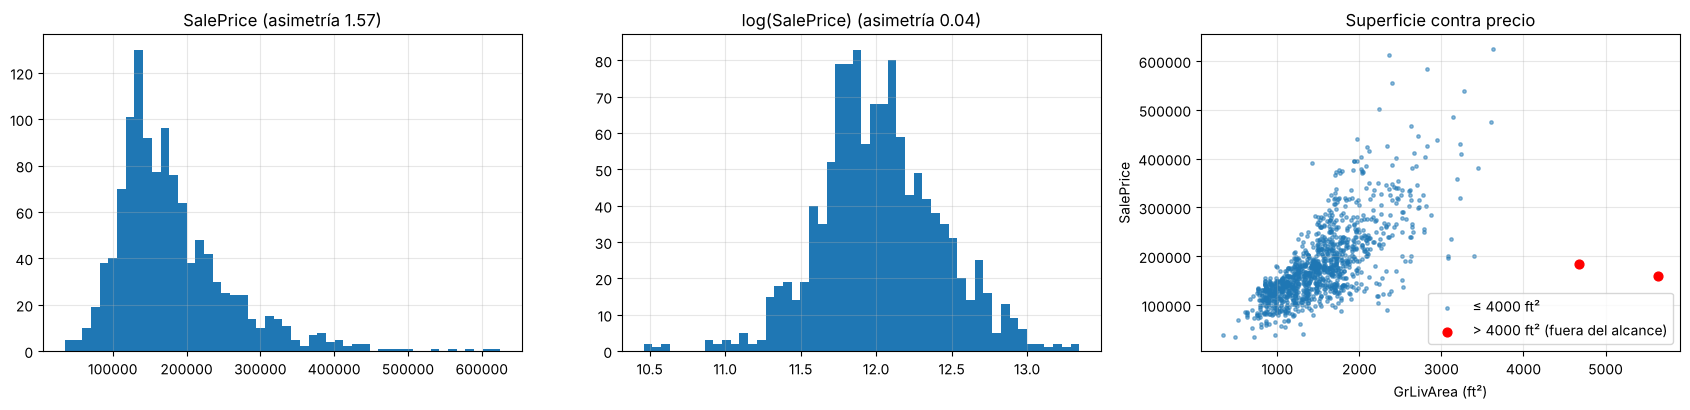

  Id  GrLivArea  SalePrice SaleType SaleCondition
1299       5642     160000      New       Partial
 524       4676     184750      New       Partial

Pares de variables de entrada con |r| > 0.75: {('GarageCars', 'GarageArea'): 0.892, ('GrLivArea', 'TotRmsAbvGrd'): 0.834, ('TotalBsmtSF', '1stFlrSF'): 0.805}
Mayor |r| con log(SalePrice): {'OverallQual': 0.81, 'GrLivArea': 0.72, 'GarageCars': 0.68, 'GarageArea': 0.66, 'TotalBsmtSF': 0.64, '1stFlrSF': 0.62}

Mediana de SalePrice por año de venta: {2006: 160000.0, 2007: 168750.0, 2008: 164000.0, 2009: 165000.0, 2010: 155000.0}
Ventas por año: {2006: 246, 2007: 268, 2008: 228, 2009: 277, 2010: 147} | meses con ventas en 2010: [1, 2, 3, 4, 5, 6, 7]


In [4]:
# Exploración, solo en entrenamiento.
crudo_tr_na = significado_na(X_tr_crudo)
resumen_na = pd.DataFrame({'"NA" en el archivo': (X_tr_crudo == 'NA').sum(), 'faltantes reales': crudo_tr_na.isna().sum()})
resumen_na = resumen_na[resumen_na.iloc[:, 0] > 0].sort_values('"NA" en el archivo', ascending=False)
resumen_na['significado'] = np.where(resumen_na['faltantes reales'] == 0, 'no tiene',
                             np.where(resumen_na['faltantes reales'] == resumen_na.iloc[:, 0], 'faltante real',
                                      'no tiene, salvo algunos faltantes'))
print(resumen_na.to_string())
por_omision = pd.read_csv('train.csv').loc[idx_tr].MasVnrType.isna().sum()
print(f"\nMasVnrType leído con los valores por omisión de pandas: {por_omision} NaN. Leído correctamente: "
      f"{(X_tr_crudo.MasVnrType == 'None').sum()} 'None' (sin chapa) y {(X_tr_crudo.MasVnrType == 'NA').sum()} faltantes reales")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(y_train, bins=50); ax[0].set_title(f'SalePrice (asimetría {y_train.skew():.2f})')
ax[1].hist(np.log(y_train), bins=50); ax[1].set_title(f'log(SalePrice) (asimetría {np.log(y_train).skew():.2f})')
ax[2].scatter(tr.GrLivArea, tr.SalePrice, s=6, alpha=0.5, label='≤ 4000 ft²')
ax[2].scatter(fuera_tr.GrLivArea, fuera_tr.SalePrice, s=40, c='red', label='> 4000 ft² (fuera del alcance)')
ax[2].set_xlabel('GrLivArea (ft²)'); ax[2].set_ylabel('SalePrice'); ax[2].legend(); ax[2].set_title('Superficie contra precio')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(fuera_tr[['Id', 'GrLivArea', 'SalePrice', 'SaleType', 'SaleCondition']].to_string(index=False))

# Correlación entre variables numéricas de entrada (umbral de 0.75 del curso) y con log(SalePrice).
num_ent = X_train.select_dtypes('number')
cor = num_ent.corr().where(np.triu(np.ones((num_ent.shape[1],) * 2, dtype=bool), 1)).stack()
print("\nPares de variables de entrada con |r| > 0.75:", cor[cor.abs() > 0.75].round(3).sort_values(ascending=False).to_dict())
print("Mayor |r| con log(SalePrice):", num_ent.corrwith(np.log(y_train)).abs().sort_values(ascending=False).head(6).round(2).to_dict())
print("\nMediana de SalePrice por año de venta:", tr.groupby('YrSold').SalePrice.median().to_dict())
print("Ventas por año:", tr.YrSold.value_counts().sort_index().to_dict(),
      "| meses con ventas en 2010:", sorted(tr.loc[tr.YrSold == 2010, 'MoSold'].unique().tolist()))

**Faltantes.** De las 19 columnas con "NA" en entrenamiento, en 14 el valor no es un dato perdido. Según `data_description.txt` significa que la casa no tiene ese elemento (alberca, callejón, cerca, chimenea, garaje, sótano u otras instalaciones), así que se convierte en la categoría explícita "No tiene". `GarageYrBlt` aparece como faltante porque es numérica, pero está vacía porque esas 67 casas no tienen garaje, y se elimina (inciso 2). Los faltantes reales son pocos: `LotFrontage` (214, el 18 %), `MasVnrType` y `MasVnrArea` (5 cada una), `Electrical` (1), y una casa en `BsmtExposure` y otra en `BsmtFinType2` que sí tienen sótano pero no traen el dato.

El archivo se lee con `keep_default_na=False` porque pandas, por omisión, convierte en NaN tanto "NA" como "None". En `MasVnrType` eso fusiona 686 casas sin chapa de mampostería ("None", una categoría válida) con 5 datos que realmente faltan, y deja 691 NaN indistinguibles.

**Precio.** Tiene una asimetría de 1.57 que baja a 0.04 con logaritmo, por lo que los modelos se entrenan sobre log(SalePrice) y toda predicción se regresa a dólares.

**Correlación entre variables de entrada.** Con el umbral de 0.75 que usa el curso, tres pares de numéricas están muy correlacionados: `GarageCars` y `GarageArea` (0.892), `GrLivArea` y `TotRmsAbvGrd` (0.834), y `TotalBsmtSF` y `1stFlrSF` (0.805). Las ordinales, que entran a los modelos como números, agregan tres pares más, que se calculan al definir su codificación: `GarageQual` y `GarageCond` (0.959), `Fireplaces` y `FireplaceQu` (0.865), y `BsmtFinSF2` y `BsmtFinType2` (0.801). El inciso 4 evalúa quitar una variable de cada par. Las más correlacionadas con log(SalePrice) son `OverallQual` (0.81) y `GrLivArea` (0.72).

**Casas fuera del alcance.** Las dos casas de más de 4,000 ft² que cayeron en entrenamiento son ventas *Partial*, casas nuevas vendidas antes de terminarse, por 160,000 y 184,750 USD, muy por debajo de lo que indica su tamaño. La gráfica las muestra lejos del resto. El inciso 4 mide qué pasaría si se usaran para entrenar.

In [5]:
# Procesamiento que SÍ aprende de los datos (imputación, codificación, escalamiento): va dentro de un Pipeline,
# de modo que se ajusta solo con el entrenamiento de cada pliegue. Las decisiones se justifican en los incisos 3 a 6.
ESCALA_CALIDAD = ['No tiene', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
ORDINALES = {
    'ExterQual': ESCALA_CALIDAD, 'ExterCond': ESCALA_CALIDAD, 'BsmtQual': ESCALA_CALIDAD,
    'BsmtCond': ESCALA_CALIDAD, 'HeatingQC': ESCALA_CALIDAD, 'KitchenQual': ESCALA_CALIDAD,
    'FireplaceQu': ESCALA_CALIDAD, 'GarageQual': ESCALA_CALIDAD, 'GarageCond': ESCALA_CALIDAD,
    'BsmtExposure': ['No tiene', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['No tiene', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['No tiene', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['No tiene', 'Unf', 'RFn', 'Fin'],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'LotShape': ['IR3', 'IR2', 'IR1', 'Reg'], 'LandSlope': ['Sev', 'Mod', 'Gtl'],
    'PavedDrive': ['N', 'P', 'Y'], 'CentralAir': ['N', 'Y'],
}

def columnas(X):
    ordinales = [c for c in ORDINALES if c in X.columns]
    nominales = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c]) and c not in ordinales]
    numericas = [c for c in X.columns if c not in ordinales and c not in nominales]
    return numericas, ordinales, nominales

def preprocesador(X, escalar=True, drop=None, min_frec=0.01, imputacion='median', transformacion='estandar'):
    """escalar=True para los modelos sensibles a la escala (lineales, MLP, SVM) y False para los de árboles.
    drop='first' solo en la regresión lineal sin regularizar (inciso 6)."""
    numericas, ordinales, nominales = columnas(X)
    num = [('imputa', SimpleImputer(strategy=imputacion))]
    # Un valor fuera de la escala se trata como faltante y se imputa, en lugar de detener la predicción.
    orde = [('codifica', OrdinalEncoder(categories=[ORDINALES[c] for c in ordinales],
                                        handle_unknown='use_encoded_value', unknown_value=np.nan)),
            ('imputa', SimpleImputer(strategy='most_frequent'))]
    if escalar:
        if transformacion == 'yeo-johnson':
            num.append(('potencia', PowerTransformer(method='yeo-johnson', standardize=True)))
        else:                                              # 'estandar' es la elegida; log1p se evalúa en el inciso 4
            if transformacion == 'log1p':
                num.append(('log1p', FunctionTransformer(np.log1p)))
            num.append(('escala', StandardScaler()))
        orde.append(('escala', StandardScaler()))
    nom = [('imputa', SimpleImputer(strategy='most_frequent')),
           ('ohe', OneHotEncoder(drop=drop, handle_unknown='ignore',
                                 min_frequency=min_frec, sparse_output=False))]
    return ColumnTransformer([('num', Pipeline(num), numericas), ('ord', Pipeline(orde), ordinales),
                              ('nom', Pipeline(nom), nominales)])

numericas, ordinales, nominales = columnas(X_train)
print(f"Numéricas ({len(numericas)}): {numericas}\n")
print(f"Ordinales ({len(ordinales)}): {ordinales}\n")
print(f"Nominales ({len(nominales)}): {nominales}")

# Correlación incluyendo las ordinales ya codificadas (entran a los modelos como números), con el umbral de 0.75 del curso.
cod = X_train[numericas].join(pd.DataFrame({c: X_train[c].map({v: k for k, v in enumerate(ORDINALES[c])}) for c in ordinales}))
cor_o = cod.corr().where(np.triu(np.ones((cod.shape[1],) * 2, dtype=bool), 1)).stack()
print("\nPares con |r| > 0.75, incluyendo las ordinales codificadas:",
      cor_o[cor_o.abs() > 0.75].round(3).sort_values(ascending=False).to_dict())

Numéricas (32): ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal', 'AgeHouse', 'AgeRemod', 'TieneAlberca']

Ordinales (18): ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'Functional', 'LotShape', 'LandSlope', 'PavedDrive', 'CentralAir']

Nominales (24): ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electri

Las variables se agrupan en tres tipos, y cada grupo tiene su propio tratamiento dentro del `Pipeline`.

| Tipo | Cuántas | Tratamiento |
| --- | --- | --- |
| Numéricas | 32 | Imputación con la mediana. En los modelos sensibles a la escala (lineales, MLP y SVR), estandarización. Los árboles las usan sin transformar |
| Ordinales | 18 | Codificación con el orden real de cada escala, por ejemplo No tiene < Po < Fa < TA < Gd < Ex, de modo que "No tiene" queda como el nivel más bajo. Un valor que no está en la escala se trata como faltante. Imputación con la moda para los dos faltantes de sótano |
| Nominales | 24 | Imputación con la moda (5 en `MasVnrType` y 1 en `Electrical`). One-Hot con las categorías de menos de 1 % agrupadas en una sola columna. Una categoría que el entrenamiento nunca vio se codifica con ceros, sin asignarla a ninguna categoría conocida |

No hay variables cíclicas en el modelo final, porque `MoSold` se elimina (inciso 3). El inciso 4 compara la estandarización simple con Yeo-Johnson y con log1p.

In [6]:
# Utilidades comunes. El objetivo se modela como log(SalePrice) estandarizado, pero toda predicción y
# toda métrica regresan a dólares: TransformedTargetRegressor invierte la transformación al predecir.
def con_log(preprocesamiento, modelo):
    objetivo = Pipeline([('log', FunctionTransformer(np.log, inverse_func=np.exp, check_inverse=False)),
                         ('escala', StandardScaler())])
    return TransformedTargetRegressor(regressor=Pipeline([('prep', preprocesamiento), ('modelo', modelo)]),
                                      transformer=objetivo)

METRICAS = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'r2': 'r2', 'mape': 'neg_mean_absolute_percentage_error'}
P = 'regressor__modelo__'                 # prefijo de los hiperparámetros dentro del pipeline
resultados, mejores, pliegues = {}, {}, {}

def ajusta(nombre, estimador, malla, aleatoria=False, n_iter=40):
    """Búsqueda con validación cruzada (refit por RMSE). Registra métricas de validación cruzada y de entrenamiento;
    la prueba no interviene aquí."""
    t0 = time.time()
    if aleatoria:
        bus = RandomizedSearchCV(estimador, malla, n_iter=n_iter, scoring=METRICAS, refit='rmse', cv=kf,
                                 n_jobs=-1, return_train_score=True, random_state=RANDOM_STATE)
    else:
        bus = GridSearchCV(estimador, malla, scoring=METRICAS, refit='rmse', cv=kf,
                           n_jobs=-1, return_train_score=True)
    bus.fit(X_train, y_train)
    r, i = bus.cv_results_, bus.best_index_
    resultados[nombre] = {
        'RMSE_train': -r['mean_train_rmse'][i], 'RMSE_cv': -r['mean_test_rmse'][i], 'RMSE_cv_std': r['std_test_rmse'][i],
        'MAE_cv': -r['mean_test_mae'][i], 'R2_cv': r['mean_test_r2'][i], 'MAPE_cv_%': -100 * r['mean_test_mape'][i],
        't_ajuste_s': bus.refit_time_, 't_busqueda_s': time.time() - t0, 'R2_train': r['mean_train_r2'][i],
        'MAE_train': -r['mean_train_mae'][i], 'MAPE_train_%': -100 * r['mean_train_mape'][i]}
    pliegues[nombre] = np.array([-r[f'split{k}_test_rmse'][i] for k in range(kf.get_n_splits())])
    mejores[nombre] = bus.best_estimator_
    params = {k.replace(P, ''): (round(float(v), 5) if isinstance(v, (float, np.floating)) else
              int(v) if isinstance(v, np.integer) else v) for k, v in bus.best_params_.items()}
    print(f"{nombre}: {len(r['params'])} combinaciones, mejores hiperparámetros {params}")
    print(f"  RMSE entrenamiento {resultados[nombre]['RMSE_train']:,.0f} | CV {resultados[nombre]['RMSE_cv']:,.0f} "
          f"± {resultados[nombre]['RMSE_cv_std']:,.0f} | MAE CV {resultados[nombre]['MAE_cv']:,.0f} | "
          f"búsqueda {resultados[nombre]['t_busqueda_s']:.0f} s")
    return bus

def curva_aprendizaje(nombre, ax=None):
    tam, tr_, va = learning_curve(clone(mejores[nombre]), X_train, y_train, cv=kf, n_jobs=-1,
                                  train_sizes=np.linspace(0.1, 1.0, 8), scoring='neg_root_mean_squared_error')
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    ax.plot(tam, -tr_.mean(1), 'o-', label='Entrenamiento')
    ax.plot(tam, -va.mean(1), 'o-', label='Validación cruzada')
    ax.fill_between(tam, np.maximum(-va.mean(1) - va.std(1), 0), -va.mean(1) + va.std(1), alpha=0.2)
    ax.set_xlabel('Casas de entrenamiento'); ax.set_ylabel('RMSE (USD)')
    ax.set_title(f'Curva de aprendizaje: {nombre}'); ax.grid(alpha=0.3); ax.legend()
    plt.show()
    print(f"Con todo el entrenamiento: RMSE entrenamiento {-tr_.mean(1)[-1]:,.0f}, validación {-va.mean(1)[-1]:,.0f}, "
          f"brecha {(-va.mean(1)[-1]) - (-tr_.mean(1)[-1]):,.0f}")

# Modelos de referencia para la evidencia de los incisos 3, 4 y 6, con hiperparámetros fijos: Ridge (lineal),
# XGBoost (árboles) y SVR con kernel radial (con los valores de C y gamma que después elige la búsqueda del
# inciso 9f, para medir el efecto del procesamiento en el modelo final).
REFERENCIAS = ['Ridge', 'XGBoost', 'SVR']
def referencia(tipo, Xr, log=True, drop=None, **kw_prep):
    if tipo == 'Ridge':
        prep = preprocesador(Xr, escalar=True, drop=drop, **kw_prep); m = Ridge(alpha=5)
    elif tipo == 'SVR':
        prep = preprocesador(Xr, escalar=True, drop=drop, **kw_prep); m = SVR(C=100, gamma=3e-4, epsilon=0.1)
    else:
        prep = preprocesador(Xr, escalar=False, drop=drop, **kw_prep)
        m = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=3, subsample=0.8,
                         colsample_bytree=0.6, random_state=RANDOM_STATE, n_jobs=1)
    return con_log(prep, m) if log else Pipeline([('prep', prep), ('modelo', m)])

def rmse_cv(est, Xr):
    """RMSE de validación cruzada por pliegue (siempre los mismos 5 pliegues, así que las comparaciones son pareadas)."""
    return -cross_validate(est, Xr, y_train, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)['test_score']

_memo = {}
def evalua_variantes(variantes):
    """variantes: {etiqueta: (parámetros de PrepararViviendas, parámetros del preprocesador, ¿precio en log?)}.
    La primera es la configuración elegida y las diferencias se miden contra ella, pliegue por pliegue."""
    filas, plg = [], {}
    for etiqueta, (kw_viv, kw_prep, log) in variantes.items():
        Xv = PrepararViviendas(**kw_viv).transform(X_tr_crudo)
        fila = {'variante': etiqueta}
        for tipo in REFERENCIAS:
            clave = (tipo, repr(kw_viv), repr(kw_prep), log)
            if clave not in _memo:
                _memo[clave] = rmse_cv(referencia(tipo, Xv, log, **kw_prep), Xv)
            plg[etiqueta, tipo] = _memo[clave]
            fila[f'RMSE {tipo}'] = _memo[clave].mean()
        filas.append(fila)
    t = pd.DataFrame(filas).set_index('variante')
    t.attrs['pliegues'] = plg
    return t

def mejora_clara(d, rmse_ref):
    """Criterio fijado antes de comparar, el mismo para el procesamiento y para los ensambles. Con los mismos 5
    pliegues (diferencias pareadas d), la alternativa debe ser mejor en al menos 4 pliegues (consistencia) y en
    promedio por más del 1 % del RMSE de la referencia (relevancia práctica)."""
    return (d < 0).sum() >= 4 and -d.mean() > 0.01 * rmse_ref

def muestra(t):
    """Se adopta una alternativa si cumple el criterio en todos los modelos de referencia a los que afecta
    (una transformación de escala no cambia nada en XGBoost, y ahí no cuenta). Si no, se queda la elegida, que en
    cada comparación es la opción más simple o la que tiene mejor justificación conceptual."""
    plg, elegida = t.attrs['pliegues'], t.index[0]
    filas = {}
    for v in t.index[1:]:
        fila, decisiones = {}, []
        for tp in REFERENCIAS:
            d = plg[v, tp] - plg[elegida, tp]
            afecta = np.abs(d).max() > 0.5
            fila[f'dif. {tp}'] = d.mean() if afecta else np.nan
            fila[f'pliegues mejores {tp}'] = f"{(d < 0).sum()} de 5 ({d.min():+,.0f} a {d.max():+,.0f})" if afecta else 'no afecta'
            if afecta:
                decisiones.append(mejora_clara(d, plg[elegida, tp].mean()))
        fila['¿adoptar?'] = 'sí' if decisiones and all(decisiones) else 'no'
        filas[v] = fila
    print(t[[f'RMSE {tp}' for tp in REFERENCIAS]].round(0).to_string())
    print('\nDiferencia media contra la configuración elegida (USD) y pliegues en que la alternativa es mejor:')
    res = pd.DataFrame(filas).T
    for tp in REFERENCIAS:
        res[f'dif. {tp}'] = res[f'dif. {tp}'].astype(float).round(0)
    print(res.to_string())
    print('\nUmbral de relevancia (1 % del RMSE de la configuración elegida):',
          {tp: round(0.01 * plg[elegida, tp].mean()) for tp in REFERENCIAS})

**Herramientas comunes.** Los modelos aprenden log(SalePrice) estandarizado mediante `TransformedTargetRegressor`, pero las predicciones y todas las métricas están en dólares. `ajusta()` hace la búsqueda de hiperparámetros con validación cruzada optimizando el RMSE y registra las métricas de validación y de entrenamiento, sin tocar la prueba.

**Cómo se comparan las alternativas de procesamiento (incisos 3, 4 y 6).** Cada alternativa se evalúa con los mismos 5 pliegues que la configuración elegida, con tres modelos de referencia muy distintos y de hiperparámetros fijos: Ridge (lineal), XGBoost (árboles) y una SVR con kernel radial, la familia que resultó mejor. Los hiperparámetros de la SVR son los que eligió la búsqueda con la configuración elegida, lo que la favorece levemente frente a las alternativas. Los de Ridge (alpha = 5) y XGBoost (600 árboles de profundidad 3) son valores típicos fijos, distintos de los que eligió la búsqueda. Como los pliegues son los mismos, la comparación es pareada.

**Criterio de adopción.** Una alternativa se adopta solo si, en cada modelo de referencia al que afecta, es mejor en al menos 4 de los 5 pliegues (consistencia) y, en promedio, por más del 1 % del RMSE de la configuración elegida, unos 190 a 220 USD (relevancia práctica). Una transformación de escala, por ejemplo, no cambia nada en XGBoost, y ahí no cuenta. Si no cumple, se conserva la configuración elegida, que en cada comparación es la opción más simple o la de mejor justificación conceptual. El mismo criterio decide después si conviene un ensamble (inciso 15). Es un criterio heurístico: con 5 pliegues no hay potencia para una prueba estadística formal, y lo que se busca es no adoptar cambios que dependan de qué casas cayeron en cada pliegue.

## **Inciso 1. `YrSold`**

> Justificar la decisión tomada en la variable “YrSold”.

**`YrSold` se elimina.** La razón principal es la de la consigna: la actividad simula la valuación de una casa en un solo momento, y el año de venta no describe a la casa sino al mercado en el que se vendió. Un modelo que la use aprende un efecto del momento económico que no se puede trasladar a otra fecha. Un árbol trataría cualquier año posterior como si fuera 2010, y un modelo lineal extrapolaría cualquier tendencia que haya visto, y ninguna de las dos cosas tiene sentido para valuar una casa hoy.

En estos datos, además, el efecto del año es débil y sin una tendencia clara. En entrenamiento, la mediana del precio va de 160,000 USD en 2006 a 168,750 USD en 2007, baja a 164,000 y 165,000 USD en 2008 y 2009, en plena crisis hipotecaria, y llega a 155,000 USD en 2010, que solo incluye ventas de enero a julio. Con entre 147 y 277 ventas por año, esas diferencias son pequeñas frente a la variación de precios dentro de cada año.

**Límite de esta decisión.** Eliminar `YrSold` no actualiza los precios a 2026. El modelo sigue aprendiendo precios en dólares de 2006 a 2010, sin ajuste por inflación ni por la evolución del mercado, y lo único que se logra es que no intente extrapolar una tendencia temporal. Para valuar casas hoy habría que reentrenarlo con ventas recientes (inciso 16).

## **Inciso 2. `YearBuilt` y `YearRemodAdd` como edades**

> Justificar la decisión tomada con las variables “YearBuild” y “YearRemodAdd”. Además, una vez transformadas en las nuevas variables, ¿deben seguir conservándose como variables de entrada o debemos eliminarlas? ¿Por qué?

In [7]:
# Inciso 2. Verificación de las restricciones sobre la entrada ya preparada (entrenamiento).
print("Correlación AgeHouse contra YearBuilt:", round(np.corrcoef(X_train.AgeHouse, tr.YearBuilt)[0, 1], 6))
print("Correlación AgeRemod contra YearRemodAdd:", round(np.corrcoef(X_train.AgeRemod, tr.YearRemodAdd)[0, 1], 6))
print("Edad de las casas: de", X_train.AgeHouse.min(), "a", X_train.AgeHouse.max(), "años | diferencia con la edad al venderse:",
      sorted((ANIO_ACTUAL - tr.YrSold).unique().tolist()))
eliminadas = ['YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold']
print("Columnas de entrada:", X_train.shape[1], "| conservadas: AgeHouse y AgeRemod |",
      "eliminadas presentes:", [c for c in eliminadas if c in X_train.columns])
gyb = crudo_tr_na.GarageYrBlt
print("Correlación GarageYrBlt contra YearBuilt:", round(gyb.corr(tr.YearBuilt), 3),
      f"| casas sin garaje (GarageYrBlt vacío): {gyb.isna().sum()}")
print("YearRemodAdd igual a 1950 (valor mínimo registrado):", (tr.YearRemodAdd == 1950).sum(),
      "| de ellas construidas antes de 1950:", ((tr.YearRemodAdd == 1950) & (tr.YearBuilt < 1950)).sum(),
      "| construidas en 1950:", ((tr.YearRemodAdd == 1950) & (tr.YearBuilt == 1950)).sum())
print("Utilities:", X_tr_crudo.Utilities.value_counts().to_dict())

Correlación AgeHouse contra YearBuilt: -1.0
Correlación AgeRemod contra YearRemodAdd: -1.0
Edad de las casas: de 17 a 154 años | diferencia con la edad al venderse: [16, 17, 18, 19, 20]
Columnas de entrada: 74 | conservadas: AgeHouse y AgeRemod | eliminadas presentes: []
Correlación GarageYrBlt contra YearBuilt: 0.832 | casas sin garaje (GarageYrBlt vacío): 67
YearRemodAdd igual a 1950 (valor mínimo registrado): 147 | de ellas construidas antes de 1950: 139 | construidas en 1950: 8
Utilities: {'AllPub': 1165, 'NoSeWa': 1}


**Las edades se conservan y las variables originales se eliminan.** `AgeHouse` y `AgeRemod` quedan como variables de entrada, y `YearBuilt` y `YearRemodAdd` se eliminan (la consigna escribe `YearBuild`, pero la columna real es `YearBuilt`).

**Por qué edades.** La edad es la forma en que un valuador piensa la antigüedad de una casa, y al valuar una casa hoy se calcula igual que en el entrenamiento. Como se mide contra 2026 y no contra el año de venta, la edad contiene exactamente la misma información que el año de construcción y no es la que la casa tenía al venderse, que era entre 16 y 20 años menor. La ventaja es de interpretación, no de información.

**Por qué eliminar las originales.** La correlación entre cada edad y su año es exactamente -1.0. Conservar ambas duplica la información, provoca colinealidad perfecta en la regresión lineal (sus coeficientes dejan de estar determinados) y reparte la importancia entre dos copias de la misma variable.

**Un detalle del registro.** 147 casas tienen 1950 como año de remodelación, y 139 de ellas se construyeron antes de 1950. Todo indica que 1950 es el valor mínimo que admite el registro y no una remodelación real, así que para esas casas `AgeRemod` vale 76 años como tope. El modelo lo aprende como un valor más, porque no hay forma de recuperar el dato verdadero.

**`GarageYrBlt`.** También es un año absoluto, aunque la consigna no la menciona. Tiene una correlación de 0.832 con `YearBuilt` y está vacía en las 67 casas de entrenamiento sin garaje. Por coherencia con la restricción se evaluó convertirla en `AgeGarage`, y el inciso 4 muestra que no mejora el modelo, así que se elimina.

## **Inciso 3. `MoSold`**

> Justificar la decisión tomada con la variable “MoSold”. En caso de que la decisión haya sido transformarla de alguna manera, ¿debemos eliminar la variable original a continuación? ¿Por qué?

In [8]:
# Inciso 3. Las cuatro opciones de MoSold que pide la consigna, con los tres modelos de referencia.
ev_mosold = evalua_variantes({
    'Elegida: MoSold eliminada': ({}, {}, True),
    'MoSold numérica': (dict(mosold='numerica'), {}, True),
    'MoSold categórica': (dict(mosold='categorica'), {}, True),
    'MoSold cíclica (seno y coseno)': (dict(mosold='ciclica'), {}, True),
})
muestra(ev_mosold)

                                RMSE Ridge  RMSE XGBoost  RMSE SVR
variante                                                          
Elegida: MoSold eliminada          19670.0       21816.0   18890.0
MoSold numérica                    19619.0       21795.0   18971.0
MoSold categórica                  19753.0       22197.0   19004.0
MoSold cíclica (seno y coseno)     19688.0       21960.0   18962.0

Diferencia media contra la configuración elegida (USD) y pliegues en que la alternativa es mejor:
                                dif. Ridge pliegues mejores Ridge  dif. XGBoost pliegues mejores XGBoost  dif. SVR pliegues mejores SVR ¿adoptar?
MoSold numérica                      -51.0    4 de 5 (-103 a +41)         -21.0     3 de 5 (-604 a +581)      81.0   0 de 5 (+6 a +174)        no
MoSold categórica                     84.0    2 de 5 (-82 a +319)         381.0   2 de 5 (-290 a +1,694)     115.0  1 de 5 (-18 a +268)        no
MoSold cíclica (seno y coseno)        19.0    3 de 5 (-81 a +

**`MoSold` se elimina.** Las cuatro opciones que pide la consigna difieren en a lo más 402 USD, y ninguna cumple el criterio. La numérica es la más cercana: mejora 51 USD en Ridge, en 4 de 5 pliegues, pero eso es menos del 1 % del RMSE (197 USD), y empeora en la SVR en los 5 pliegues. La categórica empeora en los tres modelos, hasta 381 USD en XGBoost. La cíclica empeora en los tres, aunque por poco (19, 144 y 72 USD). Las diferencias por pliegue cambian de signo y van de cientos de dólares hasta unos 1,700 USD.

Conceptualmente, el mes describe el momento de la transacción y no a la casa, y en una valuación estática una casa vale lo mismo sin importar en qué mes se venda. Sin evidencia de que ayude, se elige la opción más simple. Si se quisiera conservar la estacionalidad, la forma correcta sería la cíclica, porque es la única en la que diciembre y enero quedan cerca.

**Si se hubiera transformado, la variable original sí debería eliminarse.** En la versión cíclica, el seno y el coseno ya determinan el mes por completo, así que la original sería redundante, y además devolvería la discontinuidad artificial que la transformación corrige, porque como número diciembre (12) queda lejos de enero (1) aunque son meses consecutivos. En la versión categórica, conservar también la numérica duplicaría la misma información.

**El mismo argumento aplica a `SaleType` y `SaleCondition`**, que describen la transacción (venta normal, remate, venta entre familiares, casa nueva). Se conservan como variables de control porque separan ventas que no son de mercado y tienen un efecto grande. En Lasso, una venta anormal (`SaleCondition_Abnorml`, como un remate) está entre los coeficientes más grandes y reduce el precio (inciso 10), y las ventas *Partial* concentran los errores más grandes (evaluación final). Al valuar una casa se fijan en una venta normal, `SaleType='WD'` y `SaleCondition='Normal'`, o en las de obra nueva si es el caso, de modo que la estimación es el valor en una venta normal. La evaluación final mide el modelo también con ese protocolo.

## **Inciso 4. Análisis y procesamiento de los datos**

> Realizar un análisis y procesamiento de los datos como consideren sea lo más adecuado. En particular, realicen una limpieza de datos; imputación sobre datos perdidos (media, mediana o moda); decidan qué transformaciones aplicar sobre las variables numéricas, nominales, ordinales, o cíclicas (en dado caso). Cada una de estas decisiones se espera sea la mejor de todas las consideradas. Justificar las decisiones tomadas.

La limpieza y las transformaciones ya se definieron en la preparación de los datos. Aquí se compara cada decisión contra sus alternativas.

In [9]:
# Inciso 4. Resto de las decisiones de procesamiento, contra la configuración elegida.
ev_prep = evalua_variantes({
    'Elegida: mediana, log, estandarización, min_frec 1 %': ({}, {}, True),
    'GarageYrBlt como edad (AgeGarage)': (dict(garaje='edad'), {}, True),
    'Precio sin logaritmo': ({}, {}, False),
    'Imputación con la media': ({}, dict(imputacion='mean'), True),
    'Yeo-Johnson antes de estandarizar': ({}, dict(transformacion='yeo-johnson'), True),
    'log1p antes de estandarizar': ({}, dict(transformacion='log1p'), True),
    'Categorías raras agrupadas al 3 %': ({}, dict(min_frec=0.03), True),
    'Categorías raras agrupadas al 5 %': ({}, dict(min_frec=0.05), True),
    'Categorías raras agrupadas al 10 %': ({}, dict(min_frec=0.10), True),
    'Sin agrupar categorías raras': ({}, dict(min_frec=None), True),
    'Sin GarageArea, TotRmsAbvGrd ni 1stFlrSF (|r| > 0.75)': (dict(quitar=('GarageArea', 'TotRmsAbvGrd', '1stFlrSF')), {}, True),
    'Sin GarageCond, FireplaceQu ni BsmtFinType2 (ordinales, |r| > 0.75)': (dict(quitar=('GarageCond', 'FireplaceQu', 'BsmtFinType2')), {}, True),
})
muestra(ev_prep)

# Casas fuera del alcance que cayeron en entrenamiento: se agregan al entrenamiento de cada pliegue y se evalúa en las
# mismas casas de validación, para medir solo el efecto de entrenar con ellas.
X_o, y_o = PrepararViviendas().transform(fuera_tr.drop(columns='SalePrice')), fuera_tr.SalePrice
print()
for tipo in REFERENCIAS:
    r = []
    for a, b in kf.split(X_train):
        e = referencia(tipo, X_train).fit(pd.concat([X_train.iloc[a], X_o]), pd.concat([y_train.iloc[a], y_o]))
        r.append(root_mean_squared_error(y_train.iloc[b], e.predict(X_train.iloc[b])))
    sin = ev_prep.iloc[0][f'RMSE {tipo}']
    print(f"{tipo} entrenando también con las {len(X_o)} casas de más de 4000 ft²: RMSE CV {np.mean(r):,.0f} "
          f"(sin ellas {sin:,.0f}, diferencia {np.mean(r) - sin:+,.0f}), por pliegue {np.round(r).astype(int)}")

# Lambdas que elige Yeo-Johnson en las variables más extremas (alternativa no adoptada).
pt = preprocesador(X_train, transformacion='yeo-johnson').fit(X_train).named_transformers_['num'].named_steps['potencia']
print("\nLambdas de Yeo-Johnson más extremas:", pd.Series(pt.lambdas_, index=numericas).sort_values().head(5).round(1).to_dict())

                                                                     RMSE Ridge  RMSE XGBoost  RMSE SVR
variante                                                                                               
Elegida: mediana, log, estandarización, min_frec 1 %                    19670.0       21816.0   18890.0
GarageYrBlt como edad (AgeGarage)                                       19701.0       22147.0   18899.0
Precio sin logaritmo                                                    24385.0       22456.0   78736.0
Imputación con la media                                                 19670.0       21864.0   18899.0
Yeo-Johnson antes de estandarizar                                       20287.0       21816.0   19392.0
log1p antes de estandarizar                                             21662.0       21816.0   20158.0
Categorías raras agrupadas al 3 %                                       20058.0       22397.0   19072.0
Categorías raras agrupadas al 5 %                               

Ridge entrenando también con las 2 casas de más de 4000 ft²: RMSE CV 23,874 (sin ellas 19,670, diferencia +4,204), por pliegue [24727 19413 29772 23930 21526]


XGBoost entrenando también con las 2 casas de más de 4000 ft²: RMSE CV 24,253 (sin ellas 21,816, diferencia +2,438), por pliegue [24757 25184 27654 22349 21324]


SVR entrenando también con las 2 casas de más de 4000 ft²: RMSE CV 19,507 (sin ellas 18,890, diferencia +617), por pliegue [20964 17080 22699 19095 17695]



Lambdas de Yeo-Johnson más extremas: {'TieneAlberca': -110.4, 'BsmtHalfBath': -24.5, '3SsnPorch': -10.7, 'LowQualFinSF': -9.3, 'MiscVal': -4.1}


**Decisiones de procesamiento y su justificación.** Diferencias medias de RMSE contra la configuración elegida, en Ridge, XGBoost y SVR, y número de pliegues en que la alternativa es mejor. Ninguna alternativa cumple el criterio.

| Decisión | Alternativa | Evidencia | Razón |
| --- | --- | --- | --- |
| Acotar el modelo a casas de hasta 4,000 ft² | Entrenar también con las 2 de entrenamiento | Evaluando en las mismas casas, entrenar con ellas empeora 4,204, 2,438 y 617 USD | Recomendación del autor del dataset, y el modelo queda acotado a ese alcance. La SVR es la menos afectada, lo que es coherente con su pérdida robusta (inciso 9f) |
| Precio en logaritmo | Precio en dólares | Ridge empeora 4,715 USD en los 5 pliegues y XGBoost 640 USD | Asimetría de 1.57 a 0.04, y el logaritmo vuelve aditivas relaciones multiplicativas. En la SVR la variante sin logaritmo tampoco estandariza el precio, y sus valores de C y epsilon pierden sentido en dólares (78,736 USD), así que ahí la comparación solo confirma que el objetivo debe escalarse |
| Estandarizar las numéricas (modelos sensibles a la escala) | Yeo-Johnson antes de estandarizar | +617 en Ridge y +502 en SVR, peor en 3 de 5 pliegues | Yeo-Johnson no mejora y es más compleja. En las variables casi constantes elige lambdas extremas (-110.4 en `TieneAlberca` y -24.5 en `BsmtHalfBath`), comprime las variables casi siempre en cero y vuelve el resultado frágil cuando un pliegue no tiene casos de una variable rara. XGBoost no cambia porque los árboles no usan estas transformaciones |
| Estandarizar | log1p antes de estandarizar | +1,993 en Ridge y +1,268 en SVR | Claramente peor |
| Imputación numérica con la mediana | Media | 0, +49 y +9 USD | Sin diferencia. La mediana es robusta a valores extremos, y `LotFrontage`, con 18 % faltante, tiene una cola larga |
| "NA" = "No tiene" como categoría | Imputar con la moda | Conceptual (inciso 5) | Imputar inventaría albercas, garajes y sótanos |
| Ordinales con su orden real | One-Hot | Conceptual | Conserva el orden de la escala y usa una columna en vez de seis |
| One-Hot con agrupación al 1 % | 3 %, 5 %, 10 % o sin agrupar | Al 3 %: +389, +581 y +182. Al 5 %: +762, +832 y +616. Al 10 %: +1,613, +942 y +974. Sin agrupar: +104, +879 y +235 | Todas empeoran, y más cuanto mayor es el umbral. El 5 % es la referencia que usa el curso, pero aquí agrupa vecindarios con información valiosa, y sin agrupar quedan columnas con una o dos casas |
| Conservar las variables muy correlacionadas | Quitar una de cada par con \|r\| > 0.75: numéricas (`GarageArea`, `TotRmsAbvGrd` y `1stFlrSF`) u ordinales (`GarageCond`, `FireplaceQu` y `BsmtFinType2`) | Numéricas: +68, +79 y +31 USD. Ordinales: -120 (4 de 5 pliegues), +12 y -9 USD | Ninguna cumple el criterio: quitar las ordinales mejora Ridge en 120 USD, por debajo del umbral de 197, y la SVR en 9 USD, muy dentro de la variación entre pliegues (-256 a +322). Los regularizados reparten el peso entre variables correlacionadas y los árboles usan una por división |
| Eliminar `GarageYrBlt` | `AgeGarage` | +31, +331 y +9 USD | No mejora. Correlación de 0.832 con `YearBuilt` y sin sentido para las casas sin garaje |
| `MSSubClass` nominal, sin `Utilities`, con `TieneAlberca` y chapa inconsistente como "Desconocido" | Dejarlas como están | Conceptual | Código de categoría, variable casi constante en entrenamiento (1,165 de 1,166 son `AllPub`), solo 5 albercas (inciso 5) y registros contradictorios |

En todas las comparaciones de los incisos 3 y 4, salvo quitar las tres ordinales redundantes (9 USD menos en la SVR, en 3 de 5 pliegues), la configuración elegida es además la de menor RMSE medio en la SVR, el modelo final, y el criterio confirma que ninguna alternativa la supera de forma consistente y relevante. Así, cada decisión es la mejor de las consideradas dentro del margen que el criterio puede distinguir, como pide la consigna.

## **Inciso 5. Datos perdidos de `PoolQC` y `GarageType`**

> En particular, expliquen la decisión tomada con los datos perdidos de las variables “PoolQc” y “GarageType”.

In [10]:
# Inciso 5. ¿Qué significa "NA" en PoolQC y GarageType? Tablas cruzadas en entrenamiento, con el archivo tal como viene.
print(pd.crosstab(X_tr_crudo.PoolQC, X_tr_crudo.PoolArea > 0, colnames=['PoolArea > 0']).to_string(), '\n')
sin_garaje = X_tr_crudo.GarageType == 'NA'
print(pd.crosstab(sin_garaje.rename('GarageType es NA'), (X_tr_crudo.GarageArea == 0).rename('GarageArea = 0')).to_string(), '\n')
otras = ['GarageFinish', 'GarageQual', 'GarageCond', 'GarageYrBlt']
print("Casas con GarageType 'NA' que también tienen 'NA' en", otras, ":",
      (X_tr_crudo.loc[sin_garaje, otras] == 'NA').all(axis=1).sum(), "de", sin_garaje.sum(),
      "| con GarageCars = 0:", (X_tr_crudo.loc[sin_garaje, 'GarageCars'] == 0).sum())
print("Moda de GarageType:", X_tr_crudo.loc[~sin_garaje, 'GarageType'].mode()[0],
      "| moda de PoolQC entre las casas con alberca:", X_tr_crudo.loc[X_tr_crudo.PoolArea > 0, 'PoolQC'].mode()[0])

PoolArea > 0  False  True 
PoolQC                    
Ex                0      1
Fa                0      2
Gd                0      2
NA             1161      0 

GarageArea = 0    False  True 
GarageType es NA              
False              1099      0
True                  0     67 

Casas con GarageType 'NA' que también tienen 'NA' en ['GarageFinish', 'GarageQual', 'GarageCond', 'GarageYrBlt'] : 67 de 67 | con GarageCars = 0: 67
Moda de GarageType: Attchd | moda de PoolQC entre las casas con alberca: Fa


**En ninguna de las dos el "NA" es un dato perdido.** Las tablas cruzadas lo muestran en entrenamiento. En `PoolQC`, las 1,161 casas con "NA" tienen `PoolArea` igual a 0, es decir, no tienen alberca, y solo 5 casas tienen alberca, exactamente las 5 con calidad registrada. En `GarageType`, las 67 casas con "NA" son las que no tienen garaje: las mismas 67 con `GarageArea` y `GarageCars` iguales a 0, y con "NA" también en las otras cuatro variables de garaje.

**Por eso no se imputa.** La media y la mediana no aplican a categorías, y la moda sería un error grave. En `PoolQC` asignaría a 1,161 casas sin alberca la calidad "Fa", empatada con "Gd" como la más frecuente entre las 5 que sí tienen (2 casas cada una), y en `GarageType` les daría un garaje adosado ("Attchd") a 67 casas que no tienen. Tampoco se eliminan filas, porque se perdería información real. **La decisión es crear la categoría "No tiene".** En `GarageType`, nominal, se vuelve una columna más del One-Hot.

**En `PoolQC` se va un paso más allá.** Con 5 albercas en entrenamiento, su calidad y su área no se pueden aprender. En un subconjunto de entrenamiento sin albercas, como un pliegue o un punto de la curva de aprendizaje, el preprocesamiento no aprende nada de esas variables y una casa con alberca recibe valores extremos. Los modelos flexibles, como la SVR y el MLP, pueden convertir esos valores extremos en valuaciones muy desviadas. Por eso `PoolQC` y `PoolArea` se sustituyen por un solo indicador, `TieneAlberca`, que conserva lo único aprendible: si la casa tiene alberca o no.

## **Inciso 6. El hiperparámetro `drop` de One-Hot**

> Para las variables nominales en las cuales hayan decidido aplicar la transformación One-Hot-Encoding, explicar si debe hacerse diferencia en relación con el valor del hiperparámetro “drop” cuando se usa en un modelo basado en árboles, o con en el resto de los modelos.

In [11]:
# Inciso 6. Efecto de drop en el One-Hot. (1) Trampa de las variables ficticias: con drop=None, las columnas de cada
# variable nominal suman 1, igual que la columna del intercepto, y la matriz de diseño pierde rango.
for drop in ['first', None]:
    Z = preprocesador(X_train, escalar=True, drop=drop).fit_transform(X_train)
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    print(f"drop={drop!s:5}: {Z1.shape[1]} columnas con el intercepto, rango {np.linalg.matrix_rank(Z1)}")
# (2) Efecto en el desempeño de un modelo regularizado y de uno de árboles.
for tipo in ['Ridge', 'XGBoost']:
    r = {drop: rmse_cv(referencia(tipo, X_train, drop=drop), X_train) for drop in ['first', None]}
    print(f"{tipo}: RMSE CV con drop='first' {r['first'].mean():,.0f} | con drop=None {r[None].mean():,.0f} | "
          f"drop=None mejor en {(r[None] < r['first']).sum()} de 5 pliegues")

drop=first: 169 columnas con el intercepto, rango 166
drop=None : 193 columnas con el intercepto, rango 166


Ridge: RMSE CV con drop='first' 19,684 | con drop=None 19,670 | drop=None mejor en 3 de 5 pliegues


XGBoost: RMSE CV con drop='first' 22,156 | con drop=None 21,816 | drop=None mejor en 4 de 5 pliegues


**Sí conviene distinguir, y la diferencia está en la regresión lineal sin regularizar.**

**OLS: `drop='first'`.** En un modelo lineal con intercepto, si se conservan todas las columnas de una variable nominal, su suma es 1 en todas las filas e igual a la columna del intercepto. Es la trampa de las variables ficticias, y la celda anterior la muestra: con `drop=None`, la matriz de diseño tiene 193 columnas y solo rango 166, una columna redundante por cada una de las 24 nominales y tres más. Con colinealidad perfecta, los coeficientes de mínimos cuadrados no tienen una solución única. Con `drop='first'` la categoría eliminada queda como referencia.

Aun así quedan tres redundancias (169 columnas, rango 166), y vienen de los datos. `BldgType_Duplex` y `MSSubClass_MS90` son exactamente la misma columna, porque en el diccionario el código 90 de `MSSubClass` significa "Duplex". Y como la estandarización es lineal, se conservan dos identidades del archivo: `GrLivArea` es la suma de `1stFlrSF`, `2ndFlrSF` y `LowQualFinSF`, y `TotalBsmtSF` es la suma de las tres áreas del sótano. scikit-learn resuelve OLS con mínimos cuadrados de norma mínima, así que las predicciones están bien definidas, pero esos coeficientes no se pueden interpretar por separado. Es una razón más para preferir los modelos regularizados.

**Ridge, Lasso y Elastic-Net: `drop=None`.** En Ridge y Elastic-Net la penalización hace que la solución sea única aun con columnas redundantes (en Lasso las predicciones son únicas, pero los coeficientes de columnas idénticas, como `BldgType_Duplex` y `MSSubClass_MS90`, pueden repartirse de forma arbitraria), y conservar todas las categorías evita que los coeficientes dependan de cuál se eligió como referencia: la penalización trata igual a todas las categorías, en lugar de esconder una dentro del intercepto. En Ridge el desempeño es prácticamente igual con ambas opciones (19,684 contra 19,670 USD).

**Árboles: `drop=None`.** Cada división pregunta por una sola columna y la colinealidad no les afecta. Si se elimina una categoría, el árbol solo puede identificarla por exclusión, con varias divisiones encadenadas, y su importancia desaparece. En XGBoost, `drop=None` da 21,816 USD contra 22,156 USD con `drop='first'`, y es mejor en 4 de 5 pliegues.

**MLP y SVR: `drop=None`.** No invierten una matriz como los mínimos cuadrados, y su regularización controla la redundancia. En la SVR con kernel radial importa además la geometría: con `drop='first'`, la categoría de referencia queda a distancia 1 de cada una de las demás, mientras que dos categorías que no son de referencia quedan a distancia √2 entre sí. Con todas las columnas, todas las categorías quedan a la misma distancia.

Además, con `drop='first'`, una categoría que el entrenamiento nunca vio se codifica igual que la categoría de referencia. Con `drop=None` se codifica con ceros y no se confunde con ninguna.

## **Inciso 7. Partición**

> Realizar una partición en entrenamiento (train), validación (val) y prueba (test) con el porcentaje que consideren más adecuado. En dado caso, si deciden usar Validación-Cruzada (con las secciones/folds que mejor consideren), entonces se entiende que aquí solo sería necesario particionarlo en dos.

**Se usa una partición en entrenamiento y prueba, con validación cruzada de 5 pliegues dentro de entrenamiento** (celda de carga, al inicio). Se separó el 20 % de las 1,460 casas antes de explorar, y tras aplicar la regla de alcance quedaron 1,166 casas de entrenamiento y 290 de prueba. Con tan pocos datos, la partición triple de 70/15/15 que el curso usa como referencia dejaría unas 218 casas para validar, y la estimación dependería mucho de cuáles tocaran. La validación cruzada usa cada casa de entrenamiento como validación una vez, y todas las decisiones del cuaderno (procesamiento, hiperparámetros, modelos y ensambles) se toman con ella. Los 5 pliegues son siempre los mismos (`KFold` con semilla fija), lo que permite comparar modelos pliegue por pliegue.

La prueba se reserva para estimar, una sola vez y al final, el desempeño del modelo ya elegido.

## **Inciso 8. Modelo base**

> Con relación a la métrica de la raíz del error cuadrático medio (RMSE), obtener el desempeño del modelo base o ingenuo.

In [12]:
# Inciso 8. Modelo base o ingenuo: predice siempre el mismo valor, aprendido solo en el entrenamiento de cada pliegue.
for estrategia in ['mean', 'median']:
    s = cross_validate(DummyRegressor(strategy=estrategia), X_train, y_train, cv=kf, scoring=METRICAS)
    print(f"Base ({estrategia}): RMSE CV {-s['test_rmse'].mean():,.0f} ± {s['test_rmse'].std():,.0f} | "
          f"MAE CV {-s['test_mae'].mean():,.0f} | MAPE CV {-100 * s['test_mape'].mean():.1f} %")
    if estrategia == 'mean':
        RMSE_BASE_CV = -s['test_rmse'].mean()

Base (mean): RMSE CV 77,509 ± 6,571 | MAE CV 57,391 | MAPE CV 36.7 %
Base (median): RMSE CV 79,128 ± 7,298 | MAE CV 55,552 | MAPE CV 32.4 %


**El modelo base predice siempre la media del precio de entrenamiento.** Su RMSE de validación cruzada es de 77,509 USD (± 6,571), con un MAE de 57,391 USD y un MAPE de 36.7 %. En prueba, al final del cuaderno, su RMSE es de 72,450 USD. La media es el valor constante que minimiza el RMSE. La mediana tiene un MAE menor (55,552 USD) pero un RMSE mayor (79,128 USD). Cualquier modelo útil debe quedar muy por debajo de estos valores.

## **Inciso 9. Entrenamiento y ajuste de los modelos**

> Deberán llevar a cabo el entrenamiento y ajuste de hiperparámetros de los modelos considerando como métrica de referencia la RMSE y evitando filtrado de información. Lleven el entrenamiento y ajuste para cada modelo por separado y mostrando en cada caso la gráfica de curvas de aprendizaje. Sin embargo, mostrar de manera tabular también el resultado de RMSE, MAE, R², MAPE y el tiempo de entrenamiento.

Cada modelo es un `Pipeline` completo, con procesamiento y regresor, de modo que la validación cruzada nunca filtra información del pliegue de validación. Los hiperparámetros se eligen con `GridSearchCV`, o con `RandomizedSearchCV` cuando son muchos y continuos (XGBoost y MLP), optimizando el RMSE. Para cada modelo se reportan RMSE, MAE, R² y MAPE en validación cruzada, las mismas métricas en entrenamiento para diagnosticar sobreentrenamiento y subentrenamiento, el tiempo de entrenamiento y de búsqueda, y la curva de aprendizaje. Se usa el criterio del curso: un modelo está sobreentrenado si su R² de entrenamiento supera al de validación por más de 3 puntos. Las métricas de prueba se reportan al final, una sola vez.

El RMSE de validación cruzada de cada modelo es el de la mejor de sus combinaciones, elegida con esos mismos pliegues, así que es algo optimista, más en los modelos con búsquedas grandes. La cifra sin ese sesgo es la de prueba.

In [13]:
# Inciso 9a. Regresión lineal múltiple: sin regularizar (OLS), Ridge, Lasso y Elastic-Net.
# drop='first' solo en OLS; en los regularizados la penalización resuelve la colinealidad (inciso 6).
ajusta('OLS', con_log(preprocesador(X_train, escalar=True, drop='first'), LinearRegression()), {})
pre_reg = lambda: preprocesador(X_train, escalar=True, drop=None)
ajusta('Ridge', con_log(pre_reg(), Ridge()), {P + 'alpha': np.logspace(-1, 3, 25)})
ajusta('Lasso', con_log(pre_reg(), Lasso(max_iter=50_000)), {P + 'alpha': np.logspace(-4, -1, 25)})
ajusta('ElasticNet', con_log(pre_reg(), ElasticNet(max_iter=50_000)),
       {P + 'alpha': np.logspace(-4, -1, 13), P + 'l1_ratio': [0.1, 0.5, 0.9, 0.95, 0.99]});
lineales = pd.DataFrame(resultados).T.loc[['OLS', 'Ridge', 'Lasso', 'ElasticNet']]
print('\n', lineales[['RMSE_train', 'RMSE_cv', 'RMSE_cv_std', 'MAE_cv']].astype(float).round(0).to_string())

OLS: 1 combinaciones, mejores hiperparámetros {}
  RMSE entrenamiento 16,083 | CV 20,944 ± 3,145 | MAE CV 14,278 | búsqueda 0 s


Ridge: 25 combinaciones, mejores hiperparámetros {'alpha': 14.67799}
  RMSE entrenamiento 17,143 | CV 19,567 ± 2,586 | MAE CV 13,723 | búsqueda 8 s


Lasso: 25 combinaciones, mejores hiperparámetros {'alpha': 0.00133}
  RMSE entrenamiento 17,399 | CV 19,459 ± 2,566 | MAE CV 13,569 | búsqueda 11 s


ElasticNet: 65 combinaciones, mejores hiperparámetros {'alpha': 0.00178, 'l1_ratio': 0.9}
  RMSE entrenamiento 17,570 | CV 19,464 ± 2,486 | MAE CV 13,574 | búsqueda 34 s

             RMSE_train  RMSE_cv  RMSE_cv_std   MAE_cv
OLS            16083.0  20944.0       3145.0  14278.0
Ridge          17143.0  19567.0       2586.0  13723.0
Lasso          17399.0  19459.0       2566.0  13569.0
ElasticNet     17570.0  19464.0       2486.0  13574.0


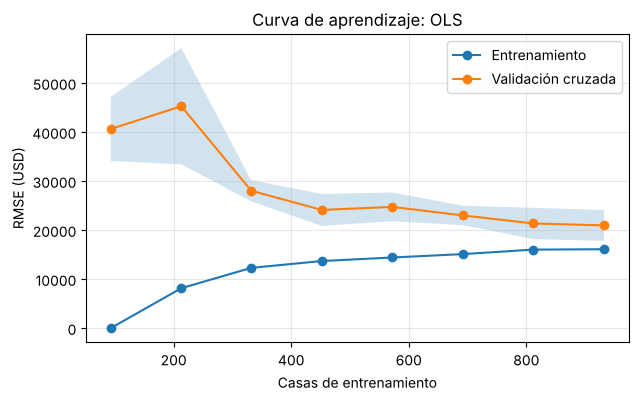

Con todo el entrenamiento: RMSE entrenamiento 16,086, validación 20,942, brecha 4,856


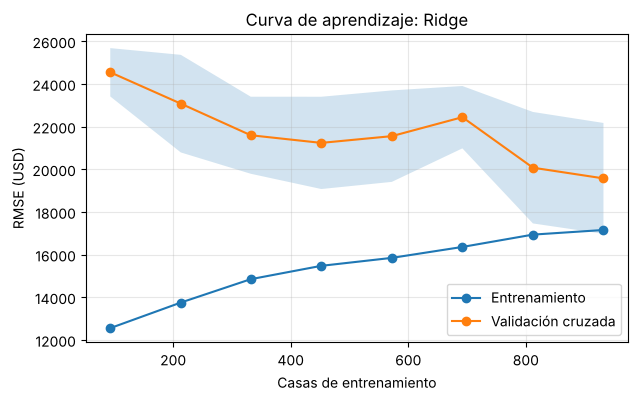

Con todo el entrenamiento: RMSE entrenamiento 17,155, validación 19,574, brecha 2,420


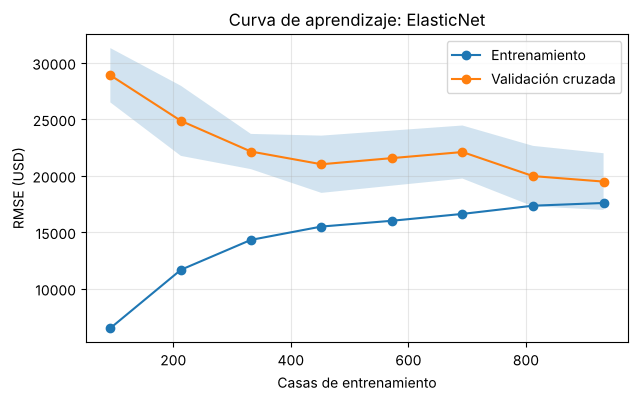

Con todo el entrenamiento: RMSE entrenamiento 17,588, validación 19,483, brecha 1,895


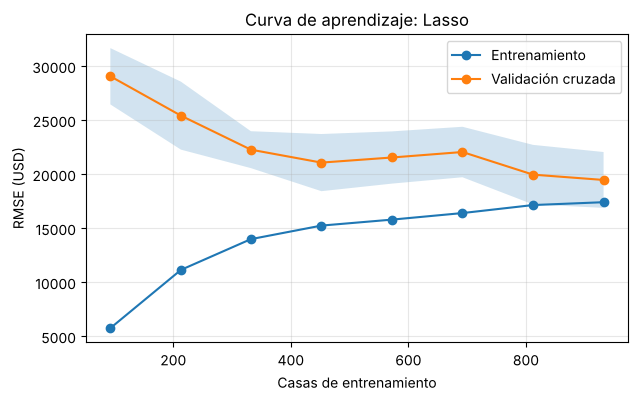

Con todo el entrenamiento: RMSE entrenamiento 17,415, validación 19,474, brecha 2,059
Lasso conserva 92 de 192 columnas después del preprocesamiento


In [14]:
for n in ['OLS', 'Ridge', 'ElasticNet', 'Lasso']:          # inciso 9: curva de cada modelo lineal
    curva_aprendizaje(n)
coef_lasso = mejores['Lasso'].regressor_.named_steps['modelo'].coef_
print(f"Lasso conserva {np.sum(coef_lasso != 0)} de {len(coef_lasso)} columnas después del preprocesamiento")

**Inciso 9a. Regresión lineal múltiple.** OLS tiene el peor RMSE de validación de los cuatro (20,944 USD) y la mayor brecha con su error de entrenamiento (16,083 USD). Sin penalización y con 168 columnas, ajusta parte del ruido. La regularización baja el RMSE de validación a entre 19,459 y 19,567 USD. Lasso (alpha de 0.0013), Elastic-Net (alpha de 0.0018 con mezcla 0.9, casi Lasso) y Ridge (alpha de 14.7) quedan a 108 USD entre sí, una diferencia irrelevante frente a desviaciones entre pliegues de unos 2,500 USD. Lasso conserva 92 de 192 columnas y descarta el resto, lo que lo vuelve el más simple de interpretar.

En las cuatro curvas de aprendizaje, entrenamiento y validación se acercan conforme crece el entrenamiento. La brecha final es de 4,856 USD en OLS y de entre 1,895 y 2,420 USD en los tres regularizados. Con pocas casas, OLS tiene más columnas que datos, ajusta el entrenamiento sin error y falla en validación, y la regularización corrige justo eso. El pico de OLS alrededor de 210 casas tiene una causa conocida: en esos subconjuntos el preprocesamiento produce unas 160 columnas, y cuando el número de casas se acerca al de columnas, la solución de mínimos cuadrados queda casi exactamente determinada y su varianza es máxima (el umbral de interpolación). Por eso no aparece en los regularizados. Los repuntes menores, alrededor de 690 casas en los regularizados, reflejan qué casas entran en ese subconjunto. Con el criterio del curso, los tres regularizados no están sobreentrenados (de 1.3 a 1.6 puntos de diferencia de R²), OLS lo está levemente (3.2 puntos), que es justo lo que corrige la regularización, y ninguno está subentrenado. La validación sigue bajando al final (en Ridge, de unos 22,400 a 19,600 USD entre 690 y 930 casas) y la brecha no se ha cerrado, así que más datos todavía ayudarían, aunque cada vez menos.

Árbol de decisión: 35 combinaciones, mejores hiperparámetros {'max_depth': 6, 'min_samples_leaf': 10}
  RMSE entrenamiento 26,766 | CV 36,660 ± 4,261 | MAE CV 25,083 | búsqueda 11 s


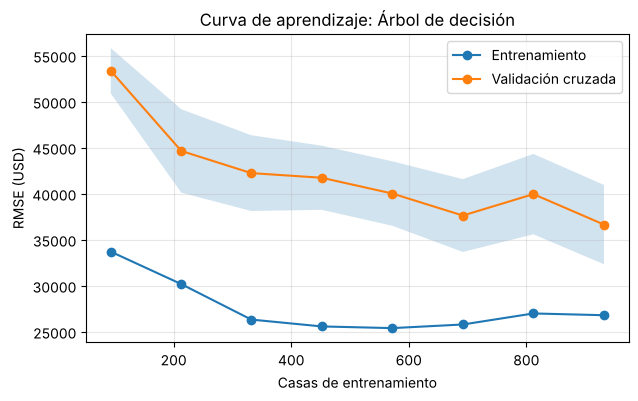

Con todo el entrenamiento: RMSE entrenamiento 26,801, validación 36,649, brecha 9,848


In [15]:
# Inciso 9b. Árbol de decisión.
ajusta('Árbol de decisión', con_log(preprocesador(X_train, escalar=False), DecisionTreeRegressor(random_state=RANDOM_STATE)),
       {P + 'max_depth': [4, 6, 8, 10, 12, 16, None], P + 'min_samples_leaf': [1, 5, 10, 20, 40]})
curva_aprendizaje('Árbol de decisión')

**Inciso 9b. Árbol de decisión.** Es el peor de los modelos (36,660 USD en validación), con profundidad 6 y hojas de al menos 10 casas. Muestra los dos problemas a la vez. Su error de entrenamiento ya es alto (26,766 USD), lo que indica subentrenamiento, porque un solo árbol predice por escalones y no reproduce bien relaciones suaves como la del precio con la superficie. Y la brecha con validación (9,848 USD en la curva) y su curva irregular indican varianza alta, porque cambiar unas cuantas casas cambia la estructura del árbol. Con el criterio del curso ya está sobreentrenado (10.6 puntos de diferencia de R²): si se le deja crecer más, la brecha aumenta, y si se poda más, pierde todavía más precisión.

Bosque aleatorio: 24 combinaciones, mejores hiperparámetros {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}
  RMSE entrenamiento 10,445 | CV 26,741 ± 2,361 | MAE CV 16,694 | búsqueda 123 s


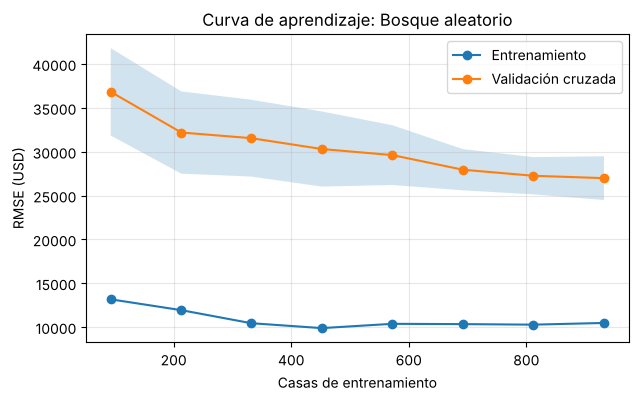

Con todo el entrenamiento: RMSE entrenamiento 10,479, validación 26,992, brecha 16,513
Misma configuración con hojas de al menos 4 casas: RMSE CV 27,560, diferencia de R² entre entrenamiento y validación 7.9 puntos


In [16]:
# Inciso 9c. Bosque aleatorio.
bus_rf = ajusta('Bosque aleatorio', con_log(preprocesador(X_train, escalar=False),
                                   RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
       {P + 'max_features': [0.2, 0.33, 0.5, 1.0], P + 'min_samples_leaf': [1, 2, 4],
        P + 'max_depth': [None, 15]})
curva_aprendizaje('Bosque aleatorio')
r_rf = pd.DataFrame(bus_rf.cv_results_)
f = r_rf[(r_rf['param_' + P + 'min_samples_leaf'] == 4) & (r_rf['param_' + P + 'max_features'] == 0.5)
         & r_rf['param_' + P + 'max_depth'].isna()]
print(f"Misma configuración con hojas de al menos 4 casas: RMSE CV {-f.mean_test_rmse.iloc[0]:,.0f}, "
      f"diferencia de R² entre entrenamiento y validación {100 * (f.mean_train_r2.iloc[0] - f.mean_test_r2.iloc[0]):.1f} puntos")

**Inciso 9c. Bosque aleatorio.** Promediar 300 árboles reduce mucho la varianza del árbol individual (26,741 USD en validación), aunque su error de entrenamiento es muy bajo (10,445 USD) y la brecha es la mayor de todos los modelos, el 61 % del error de validación (16,513 USD en la curva). Con el criterio del curso está sobreentrenado (10.2 puntos de diferencia de R²). Restringirlo no lo resuelve: con hojas de al menos 4 casas la diferencia baja a 7.9 puntos, pero el RMSE de validación sube a 27,560 USD. Por eso la búsqueda eligió árboles sin límite de profundidad y con hojas de una casa, con la mitad de las variables por división. Su problema real es de sesgo. Queda unos 7,300 USD por encima de los lineales, porque en escala logarítmica el precio depende de forma casi aditiva de la superficie, la calidad y la antigüedad, y los árboles necesitan muchas divisiones para aproximar ese tipo de relación.

XGBoost: 40 combinaciones, mejores hiperparámetros {'colsample_bytree': 0.43881, 'learning_rate': 0.00918, 'max_depth': 2, 'min_child_weight': 4, 'n_estimators': 4858, 'reg_lambda': 0.78727, 'subsample': 0.51387}
  RMSE entrenamiento 11,719 | CV 21,174 ± 1,955 | MAE CV 14,092 | búsqueda 163 s


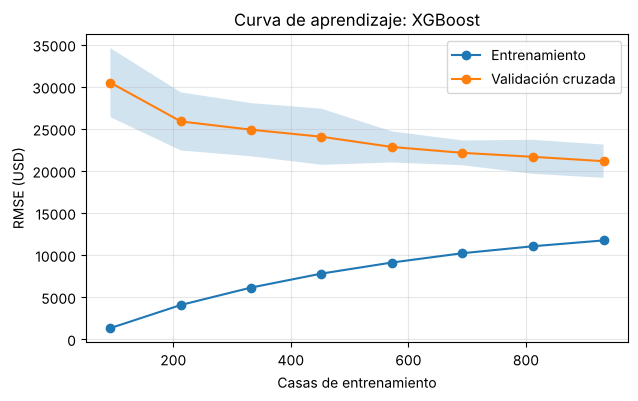

Con todo el entrenamiento: RMSE entrenamiento 11,731, validación 21,147, brecha 9,416


In [17]:
# Inciso 9d. XGBoost (búsqueda aleatoria: 7 hiperparámetros, varios continuos, no caben en una malla).
ajusta('XGBoost', con_log(preprocesador(X_train, escalar=False), XGBRegressor(random_state=RANDOM_STATE, n_jobs=1)),
       {P + 'n_estimators': randint(300, 6000), P + 'learning_rate': loguniform(0.005, 0.1),
        P + 'max_depth': randint(1, 6), P + 'min_child_weight': randint(1, 10),
        P + 'subsample': uniform(0.5, 0.5), P + 'colsample_bytree': uniform(0.2, 0.7),
        P + 'reg_lambda': loguniform(0.1, 100)}, aleatoria=True, n_iter=40)
curva_aprendizaje('XGBoost')

**Inciso 9d. XGBoost.** La búsqueda eligió 4,858 árboles de profundidad 2, con una tasa de aprendizaje baja (0.0092) y fuerte submuestreo de filas y columnas (51 % y 44 %). Árboles tan poco profundos solo capturan interacciones entre pares de variables, lo que es compatible con una estructura del problema casi aditiva. Logra 21,174 USD en validación, mucho mejor que el bosque aleatorio y cerca de los lineales, con un error de entrenamiento de 11,719 USD, una brecha del 45 % (9,416 USD en la curva). Con el criterio del curso está sobreentrenado (5.3 puntos de diferencia de R²), aunque valida razonablemente bien. Su curva de validación sigue bajando al final, así que es de los que más ganarían con más datos.

MLP: 30 combinaciones, mejores hiperparámetros {'alpha': 1.56891, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.00613}
  RMSE entrenamiento 15,350 | CV 20,510 ± 2,146 | MAE CV 14,050 | búsqueda 48 s


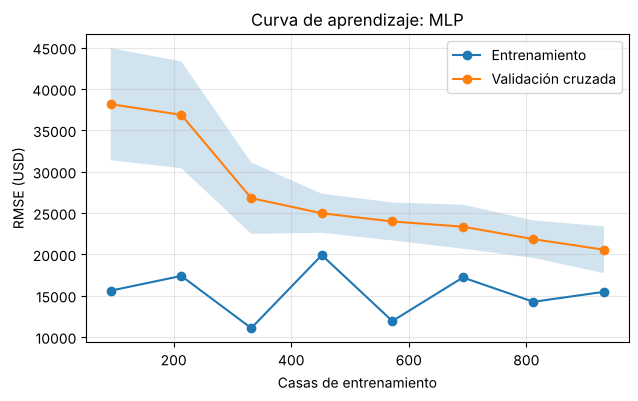

Con todo el entrenamiento: RMSE entrenamiento 15,459, validación 20,549, brecha 5,091


Mismos hiperparámetros y pliegues con las semillas 0 a 4: RMSE CV de 20,701 a 21,369 (semilla 11: 20,510)


In [18]:
# Inciso 9e. Red neuronal de perceptrón multicapa (con parada temprana sobre una fracción del entrenamiento).
ajusta('MLP', con_log(preprocesador(X_train, escalar=True),
                      MLPRegressor(max_iter=3000, early_stopping=True, random_state=RANDOM_STATE)),
       {P + 'hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
        P + 'alpha': loguniform(1e-3, 30), P + 'learning_rate_init': loguniform(1e-4, 1e-2)},
       aleatoria=True, n_iter=30)
curva_aprendizaje('MLP')
mlp_sem = [rmse_cv(clone(mejores['MLP']).set_params(regressor__modelo__random_state=sm), X_train).mean() for sm in range(5)]
print(f"Mismos hiperparámetros y pliegues con las semillas 0 a 4: RMSE CV de {min(mlp_sem):,.0f} a {max(mlp_sem):,.0f} "
      f"(semilla {RANDOM_STATE}: {resultados['MLP']['RMSE_cv']:,.0f})")

**Inciso 9e. Red neuronal MLP.** La mejor configuración tiene una capa oculta de 64 neuronas, regularización L2 con alpha de 1.57 y parada temprana. Su RMSE de validación (20,510 USD) queda entre OLS y los lineales regularizados. Que una red regularizada no supere a los modelos lineales concuerda con la estructura casi lineal del problema en escala logarítmica, y con 1,166 casas una red más grande no tiene datos suficientes para aprovechar su capacidad.

Con el criterio del curso está levemente sobreentrenado (3.2 puntos de diferencia de R²), y es el modelo de comportamiento más irregular. Su resultado depende también de la inicialización: con los mismos hiperparámetros y pliegues, pero con las semillas 0 a 4, su RMSE de validación va de 20,701 a 21,369 USD, contra 20,510 USD con la semilla del cuaderno. Como la búsqueda usó una sola semilla, eligió en parte la configuración que mejor le sienta a esa inicialización, así que su cifra es algo optimista. Su curva de entrenamiento sube y baja según el tamaño de la muestra, porque la parada temprana separa internamente un 10 % del entrenamiento para decidir cuándo parar, y esa separación y la época de corte cambian con cada tamaño. La brecha final es de 5,091 USD (25 %), y la validación sigue bajando al final de la curva.

SVR: 95 combinaciones, mejores hiperparámetros {'C': 100, 'epsilon': 0.1, 'gamma': 0.0003, 'kernel': 'rbf'}
  RMSE entrenamiento 14,520 | CV 18,890 ± 2,412 | MAE CV 12,757 | búsqueda 93 s
  Mejor kernel linear: RMSE CV 19,342
  Mejor kernel rbf: RMSE CV 18,890


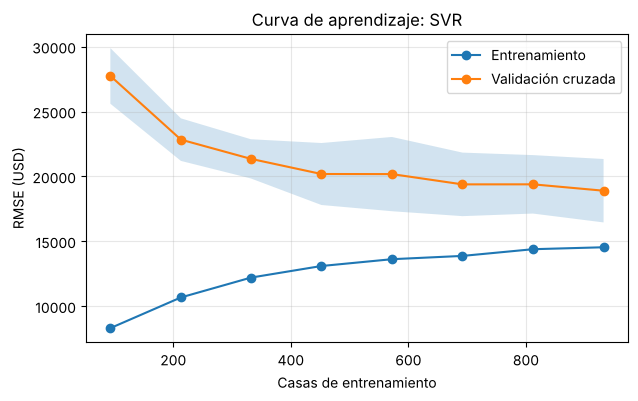

Con todo el entrenamiento: RMSE entrenamiento 14,540, validación 18,897, brecha 4,357


In [19]:
# Inciso 9f. Máquina de vector soporte para regresión (SVR) con kernel lineal y radial.
bus_svr = ajusta('SVR', con_log(preprocesador(X_train, escalar=True), SVR()),
       [{P + 'kernel': ['rbf'], P + 'C': [10, 30, 100, 300, 1000], P + 'epsilon': [0.02, 0.05, 0.1, 0.2],
         P + 'gamma': [3e-5, 1e-4, 3e-4, 1e-3]},
        {P + 'kernel': ['linear'], P + 'C': [0.003, 0.01, 0.03, 0.1, 0.3], P + 'epsilon': [0.05, 0.1, 0.2]}])
r_svr = pd.DataFrame(bus_svr.cv_results_)
for kernel, g in r_svr.groupby('param_' + P + 'kernel'):
    print(f"  Mejor kernel {kernel}: RMSE CV {-g.mean_test_rmse.max():,.0f}")
curva_aprendizaje('SVR')

**Inciso 9f. Máquina de vector soporte (SVR).** Es el mejor modelo, con 18,890 USD en validación. Usa kernel radial con C = 100, gamma = 0.0003 y epsilon = 0.1 (este último en unidades del logaritmo estandarizado del precio), los tres valores interiores de la malla. Un gamma tan pequeño hace que el kernel varíe muy despacio, así que el modelo es esencialmente una regresión casi lineal con una curvatura suave, coherente con la estructura casi aditiva del problema. Su pérdida ignora los errores menores a epsilon y crece de forma lineal, no cuadrática, con los errores grandes, lo que la hace más robusta a casas atípicas que los mínimos cuadrados. Por eso, de los tres modelos de referencia, es al que menos le afecta entrenar con las casas de más de 4,000 ft² (inciso 4). El kernel lineal también se evaluó y fue peor (19,342 USD). La brecha final en la curva de aprendizaje es de 4,357 USD, moderada, y la validación sigue bajando despacio. Con el criterio del curso no está sobreentrenada (2.6 puntos de diferencia de R²).

                   RMSE_train  RMSE_cv  RMSE_cv_std  brecha_%  MAE_train   MAE_cv  R2_train  R2_cv  dif_R2_pts  MAPE_train_%  MAPE_cv_%  t_entrenamiento_s  t_busqueda_hiperparam_s sobreentrenado
SVR                   14520.0  18890.0       2412.0      23.1     9509.0  12757.0     0.965  0.939         2.6          5.74       7.70               0.22                     93.0             no
Lasso                 17399.0  19459.0       2566.0      10.6    12080.0  13569.0     0.950  0.936         1.4          7.08       8.01               0.09                     11.0             no
ElasticNet            17570.0  19464.0       2486.0       9.7    12210.0  13574.0     0.949  0.936         1.3          7.16       8.03               0.08                     34.0             no
Ridge                 17143.0  19567.0       2586.0      12.4    12009.0  13723.0     0.951  0.935         1.6          7.07       8.16               0.09                      8.0             no
MLP                   153

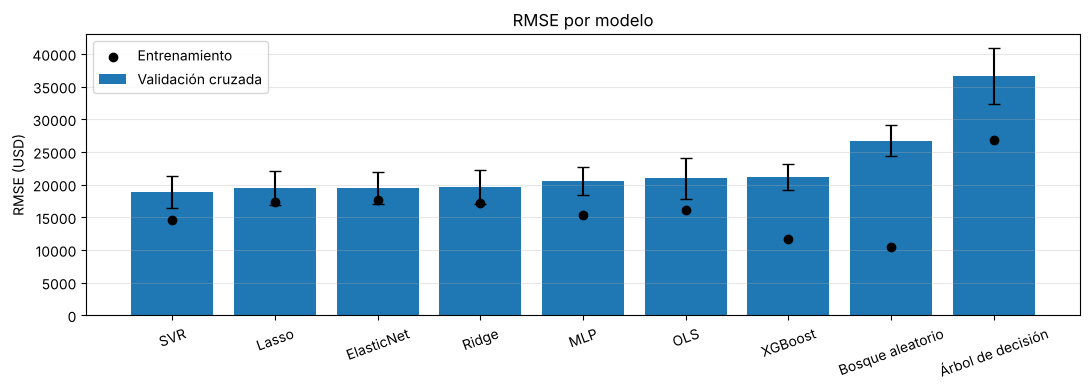

In [20]:
# Resumen del inciso 9: métricas de validación cruzada y de entrenamiento, y tiempos. La prueba se reporta al final.
tabla = pd.DataFrame(resultados).T.astype(float)
tabla['brecha_%'] = 100 * (tabla.RMSE_cv - tabla.RMSE_train) / tabla.RMSE_cv
tabla['dif_R2_pts'] = 100 * (tabla.R2_train - tabla.R2_cv)     # criterio del curso: más de 3 puntos es sobreentrenamiento
tabla = tabla.sort_values('RMSE_cv')
cols = ['RMSE_train', 'RMSE_cv', 'RMSE_cv_std', 'brecha_%', 'MAE_train', 'MAE_cv', 'R2_train', 'R2_cv', 'dif_R2_pts',
        'MAPE_train_%', 'MAPE_cv_%', 't_ajuste_s', 't_busqueda_s']
redondeo = {c: 0 for c in cols} | {'R2_train': 3, 'R2_cv': 3, 'dif_R2_pts': 1, 'MAPE_train_%': 2, 'MAPE_cv_%': 2,
                                   't_ajuste_s': 2, 'brecha_%': 1}
t_imp = tabla[cols].round(redondeo).rename(columns={'t_ajuste_s': 't_entrenamiento_s', 't_busqueda_s': 't_busqueda_hiperparam_s'})
t_imp['sobreentrenado'] = np.where(tabla.dif_R2_pts > 3, 'sí', 'no')
print(t_imp.to_string())
print(f"\nModelo base (media), RMSE CV: {RMSE_BASE_CV:,.0f}")
INDIVIDUALES = list(tabla.index)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(tabla.index, tabla.RMSE_cv, yerr=tabla.RMSE_cv_std, capsize=4, label='Validación cruzada')
ax.scatter(tabla.index, tabla.RMSE_train, color='k', zorder=3, label='Entrenamiento')
ax.set_ylabel('RMSE (USD)'); ax.set_title('RMSE por modelo'); ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [21]:
# Robustez de la comparación: mismos hiperparámetros, 10 particiones distintas en 5 pliegues (semillas 0 a 9).
# Estos pliegues no son los que eligieron los hiperparámetros, así que también se reduce el sesgo de selección.
ROBUSTOS = ['SVR', 'Lasso', 'ElasticNet', 'Ridge', 'MLP', 'OLS', 'XGBoost']
rep = {n: [] for n in ROBUSTOS}
for semilla in range(10):
    kf_s = KFold(n_splits=5, shuffle=True, random_state=semilla)
    for n in ROBUSTOS:
        sc = cross_validate(clone(mejores[n]), X_train, y_train, cv=kf_s, n_jobs=-1,
                            scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'})
        rep[n].append((-sc['test_rmse'].mean(), -sc['test_mae'].mean()))
rep = {n: np.array(v) for n, v in rep.items()}
rob = pd.DataFrame({f'RMSE_cv (semilla {RANDOM_STATE})': [resultados[n]['RMSE_cv'] for n in ROBUSTOS],
                    'RMSE medio (10 particiones)': [rep[n][:, 0].mean() for n in ROBUSTOS],
                    'mín.': [rep[n][:, 0].min() for n in ROBUSTOS], 'máx.': [rep[n][:, 0].max() for n in ROBUSTOS],
                    'RMSE+MAE medio': [rep[n].sum(1).mean() for n in ROBUSTOS]}, index=ROBUSTOS)
print(rob.round(0).sort_values('RMSE medio (10 particiones)').to_string())
gan = pd.DataFrame({n: rep[n][:, 0] for n in ROBUSTOS}).idxmin(axis=1)
d = rep['SVR'][:, 0] - rep['Lasso'][:, 0]
print(f"\nMejor modelo por partición: {gan.value_counts().to_dict()} | SVR contra Lasso: de {d.min():+,.0f} a {d.max():+,.0f} USD")
top3_rep = [tuple(pd.Series({n: rep[n][k].sum() for n in ROBUSTOS}).nsmallest(3).index) for k in range(10)]
print("Tres mejores por RMSE + MAE en cada partición:", pd.Series(top3_rep).value_counts().to_dict())
print(f"XGBoost con menor RMSE + MAE que el MLP en {(rep['XGBoost'].sum(1) < rep['MLP'].sum(1)).sum()} de 10 particiones")

            RMSE_cv (semilla 11)  RMSE medio (10 particiones)     mín.     máx.  RMSE+MAE medio
SVR                      18890.0                      19037.0  18828.0  19342.0         31844.0
Lasso                    19459.0                      19934.0  19750.0  20229.0         33649.0
ElasticNet               19464.0                      19966.0  19765.0  20298.0         33715.0
Ridge                    19567.0                      20088.0  19888.0  20509.0         33978.0
XGBoost                  21174.0                      20876.0  20676.0  21169.0         34795.0
MLP                      20510.0                      21193.0  20437.0  23671.0         35562.0
OLS                      20944.0                      21273.0  20942.0  21569.0         35634.0

Mejor modelo por partición: {'SVR': 10} | SVR contra Lasso: de -1,327 a -553 USD
Tres mejores por RMSE + MAE en cada partición: {('SVR', 'Lasso', 'ElasticNet'): 10}
XGBoost con menor RMSE + MAE que el MLP en 8 de 10 particiones


**Resumen del inciso 9.** Diagnóstico con el criterio del curso (diferencia de R² entre entrenamiento y validación mayor a 3 puntos).

| Diagnóstico | Modelos |
| --- | --- |
| Sin sobreentrenamiento (de 1.3 a 2.6 puntos) | SVR, Lasso, Elastic-Net y Ridge |
| Sobreentrenamiento leve (3.2 puntos) | OLS y MLP, este con comportamiento irregular |
| Sobreentrenamiento (5.3 puntos), todavía mejorando con más datos | XGBoost |
| Sobreentrenamiento fuerte (10.2 puntos) y sesgo ante la estructura aditiva | Bosque aleatorio |
| Sobreentrenamiento (10.6 puntos) y subentrenamiento, con el peor error de entrenamiento | Árbol de decisión |

Todos los modelos superan con mucho al modelo base (77,509 USD en validación cruzada). La SVR, los cuatro lineales, el MLP y XGBoost quedan entre 18,890 y 21,174 USD, y la SVR se separa del siguiente, Lasso, por 569 USD.

**Robustez ante la partición.** Estas cifras usan una sola partición en pliegues, la misma con la que se eligieron los hiperparámetros. Con los mismos hiperparámetros y 10 particiones distintas, la SVR es la mejor en las 10 y supera a Lasso por entre 553 y 1,327 USD, así que su ventaja no depende de la partición original. Los tres mejores por RMSE + MAE son SVR, Lasso y Elastic-Net en las 10 particiones. Lo que cambia es la posición de XGBoost: en promedio queda delante del MLP y de OLS (20,876 contra 21,193 y 21,273 USD de RMSE), y en RMSE + MAE supera al MLP en 8 de 10 particiones.

En costo computacional, todos los ajustes finales tardan unos 3 segundos como máximo (el bosque), y la SVR 0.2 segundos. Lo caro es la búsqueda de hiperparámetros, que va de menos de un segundo en OLS a poco menos de 3 minutos en XGBoost, y tarda 1.5 minutos en la SVR, con 95 combinaciones por 5 pliegues.

## **Inciso 10. Factores del mejor modelo**

> Con base al mejor modelo obtenido realizar un análisis de factores, con la interpretación en base al contexto del problema.

Mejor modelo en validación cruzada: SVR


              aumento_RMSE  desv_pliegues
GrLivArea          10814.0         2522.0
OverallQual         7767.0         2370.0
AgeHouse            6511.0         1056.0
2ndFlrSF            5370.0         1636.0
1stFlrSF            4425.0         1201.0
OverallCond         2988.0          818.0
LotArea             2852.0         1846.0
TotalBsmtSF         2806.0          893.0
Neighborhood        2327.0          533.0
BsmtFinSF1          2315.0          641.0
GarageArea          1233.0          512.0
GarageCars          1140.0          383.0
KitchenQual         1011.0          658.0
MSZoning             972.0          426.0
FullBath             864.0          450.0


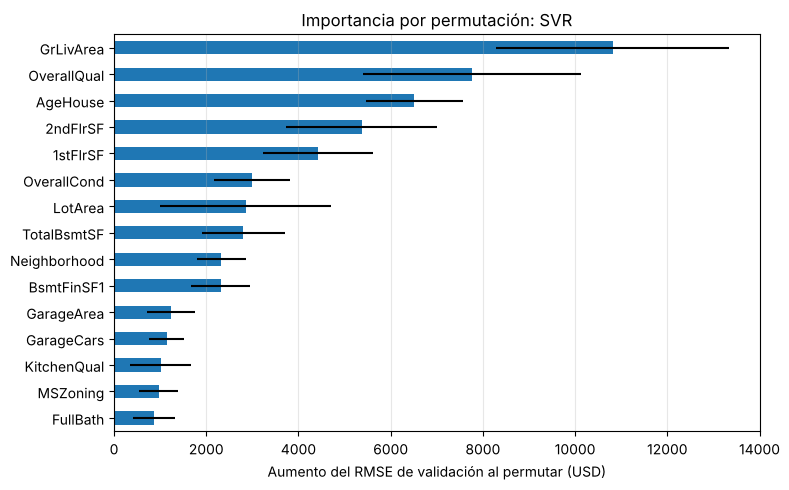

In [22]:
# Inciso 10. Factores del mejor modelo: importancia por permutación medida en la variable original (antes del One-Hot),
# dentro de la validación cruzada. En cada pliegue se ajusta el modelo con su parte de entrenamiento y se permuta en su
# parte de validación, así que la prueba no se usa.
MEJOR = tabla.RMSE_cv.idxmin()
print(f"Mejor modelo en validación cruzada: {MEJOR}")
por_pliegue = []
for a, b in kf.split(X_train):
    m = clone(mejores[MEJOR]).fit(X_train.iloc[a], y_train.iloc[a])
    r = permutation_importance(m, X_train.iloc[b], y_train.iloc[b], scoring='neg_root_mean_squared_error',
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    por_pliegue.append(r.importances_mean)
por_pliegue = np.array(por_pliegue)
imp = pd.DataFrame({'aumento_RMSE': por_pliegue.mean(0), 'desv_pliegues': por_pliegue.std(0)},
                   index=X_train.columns).sort_values('aumento_RMSE', ascending=False)
print(imp.head(15).round(0).to_string())
imp.head(15).iloc[::-1].aumento_RMSE.plot.barh(xerr=imp.head(15).iloc[::-1].desv_pliegues, figsize=(8, 5))
plt.xlabel('Aumento del RMSE de validación al permutar (USD)'); plt.title(f'Importancia por permutación: {MEJOR}')
plt.grid(alpha=0.3, axis='x'); plt.tight_layout(); plt.show()

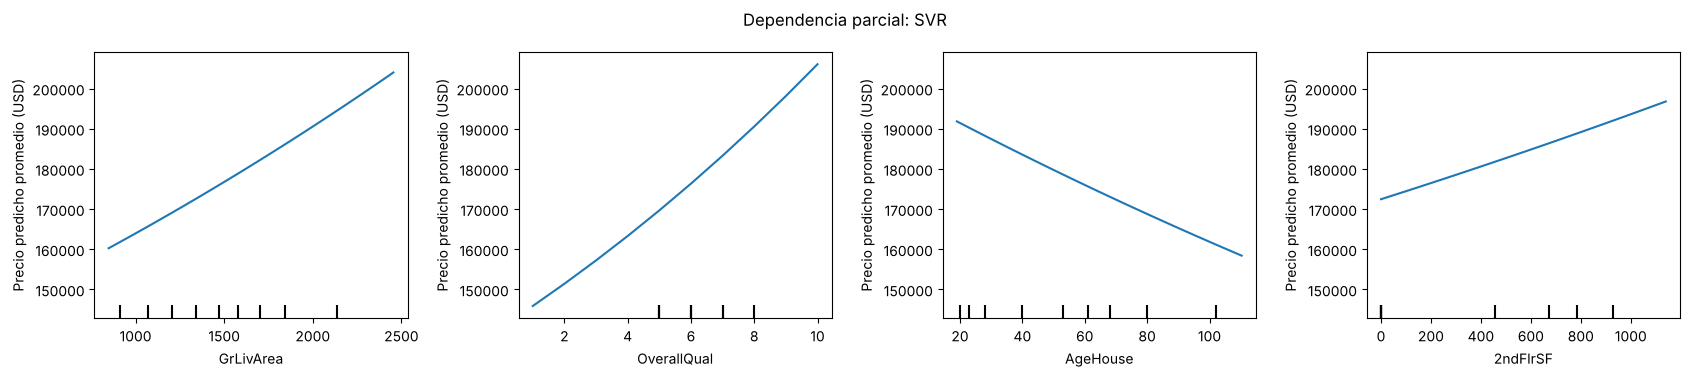

Coeficientes de Lasso más grandes:
nom__MSZoning_infrequent_sklearn   -0.877
num__GrLivArea                      0.327
nom__Neighborhood_Crawfor           0.194
num__OverallQual                    0.181
nom__SaleCondition_Abnorml         -0.178
nom__MSZoning_RM                   -0.135
nom__Neighborhood_Somerst           0.133
nom__MSSubClass_MS160              -0.132
nom__Exterior1st_BrkFace            0.126
nom__Neighborhood_StoneBr           0.121
nom__Condition1_Norm                0.118
nom__Neighborhood_BrkSide           0.118

Efecto en el precio con todo lo demás fijo (%; en las numéricas, por una desviación estándar de la variable):
nom__MSZoning_infrequent_sklearn   -29.7
num__GrLivArea                      14.0
nom__Neighborhood_Crawfor            8.1
num__OverallQual                     7.5
nom__SaleCondition_Abnorml          -6.9
nom__MSZoning_RM                    -5.3
nom__Neighborhood_Somerst            5.5
nom__MSSubClass_MS160               -5.2
nom__Exterior1st_BrkFa

In [23]:
# Dependencia parcial de las 4 variables numéricas más importantes (efecto promedio en el precio predicho).
top_num = [c for c in imp.index if c in numericas][:4]
X_pd = X_train.astype({c: float for c in numericas})       # la dependencia parcial exige columnas numéricas flotantes
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
PartialDependenceDisplay.from_estimator(mejores[MEJOR], X_pd, top_num, ax=ax, kind='average')
for a in ax: a.set_ylabel('Precio predicho promedio (USD)')
plt.suptitle(f'Dependencia parcial: {MEJOR}'); plt.tight_layout(); plt.show()

# Contraste con un modelo directamente interpretable: coeficientes de Lasso (sobre log-precio estandarizado).
lasso = mejores['Lasso'].regressor_
coef = pd.Series(lasso.named_steps['modelo'].coef_, index=lasso.named_steps['prep'].get_feature_names_out())
print("Coeficientes de Lasso más grandes:")
print(coef[coef.abs().sort_values(ascending=False).index].head(12).round(3).to_string())
sd_log = np.std(np.log(y_train))              # escala del objetivo de Lasso (StandardScaler usa ddof=0)
efecto = 100 * (np.exp(coef * sd_log) - 1)
print(f"\nEfecto en el precio con todo lo demás fijo (%; en las numéricas, por una desviación estándar de la variable):")
print(efecto[coef.abs().sort_values(ascending=False).index].head(12).round(1).to_string())
print(f"Desviación estándar de GrLivArea en entrenamiento: {X_train.GrLivArea.std(ddof=0):,.0f} ft²")

La SVR con kernel radial no tiene coeficientes interpretables, así que los factores se miden con importancia por permutación. En cada pliegue de la validación cruzada se ajusta el modelo, se desordena una variable original en la parte de validación, antes del One-Hot, y se mide cuánto aumenta el RMSE. La tabla promedia los 5 pliegues, sin usar la prueba.

| Factor | Aumento del RMSE (USD) | Lectura en el contexto inmobiliario |
| --- | --- | --- |
| Superficie habitable (`GrLivArea`, `2ndFlrSF` y `1stFlrSF`) | 10,814, 5,370 y 4,425 | El factor dominante. Las tres miden el mismo tamaño: la superficie habitable es la suma de los dos pisos, y el modelo reparte entre ellas el efecto del tamaño, que es la base de cualquier valuación |
| Calidad general (`OverallQual`) | 7,767 | Calidad de materiales y acabados en escala de 1 a 10. Dos casas del mismo tamaño valen muy distinto según sus acabados |
| Antigüedad (`AgeHouse`) | 6,511 | Las casas más nuevas valen más. Es la variable que la restricción pidió construir |
| Condición general (`OverallCond`) | 2,988 | Estado de conservación, distinto de la calidad de construcción |
| Terreno (`LotArea`) | 2,852 | Más terreno, más valor, con mucha variación entre pliegues |
| Sótano (`TotalBsmtSF` y `BsmtFinSF1`) | 2,806 y 2,315 | En Iowa el sótano es área útil adicional, y el terminado vale más |
| Vecindario (`Neighborhood`) | 2,327 | La ubicación |

Las gráficas de dependencia parcial muestran la forma de estos efectos dentro del rango habitual de cada variable. El precio predicho crece con la superficie habitable y con la calidad general, en ambos casos de forma ligeramente convexa (cada unidad adicional suma un poco más en la parte alta, lo que en buena parte es efecto de modelar el logaritmo: un aumento porcentual constante se ve convexo en dólares), baja de forma casi lineal con la antigüedad (la edad mínima es de 17 años, porque se mide contra 2026) y crece de forma lineal con la superficie del segundo piso.

Los coeficientes de Lasso, que sí son directamente interpretables, confirman el panorama. Superficie y calidad tienen coeficientes positivos grandes, varios vecindarios (Crawfor, Somerst, StoneBr y BrkSide) agregan una prima, y reducen el precio las ventas anormales (`SaleCondition_Abnorml`), la zona residencial de alta densidad (`MSZoning_RM`) y, con fuerza, la zonificación poco frecuente, que en entrenamiento corresponde a la zona comercial `C (all)`. Sus magnitudes solo se comparan entre variables del mismo tipo, porque las numéricas están estandarizadas y las columnas One-Hot no. Traducidos a porcentaje del precio, con todo lo demás fijo, la zonificación comercial lo reduce un 29.7 %, una venta anormal un 6.9 % y la zona de alta densidad un 5.3 %, estar en Crawfor lo sube un 8.1 %, y una desviación estándar más de superficie habitable (495 ft²) lo sube un 14.0 %. Son efectos encogidos por la penalización de Lasso, así que subestiman ligeramente los reales.

**Advertencia de interpretación.** La permutación reparte la importancia entre variables relacionadas, y aquí se ve con claridad en las áreas: `GrLivArea` es exactamente la suma de `1stFlrSF`, `2ndFlrSF` y `LowQualFinSF`, y `TotalBsmtSF` es la suma de las tres áreas del sótano. La importancia de cada una por separado subestima la de su grupo, que en el caso de la superficie habitable es, por mucho, la mayor. Además, al permutar una de ellas se crean casas imposibles, como una superficie total que no coincide con la de sus pisos, y lo mismo ocurre en la dependencia parcial, así que estas gráficas describen el comportamiento del modelo más que un efecto causal.

## **Inciso 11. Los tres mejores modelos con RMSE + MAE**

> Considerando como métrica la suma RMSE + MAE, selecciona los tres mejores modelos obtenidos. ¿Qué ventajas podría traer el considerar esta suma como una métrica? Explicarlo en el contexto del problema e indicando sus ventajas y desventajas.

In [24]:
# Inciso 11. Métrica combinada RMSE + MAE de validación cruzada, sobre todos los modelos ajustados en el inciso 9.
comb = tabla[['RMSE_cv', 'MAE_cv']].copy()
comb['RMSE+MAE'] = comb.RMSE_cv + comb.MAE_cv
comb = comb.sort_values('RMSE+MAE')
FAMILIA = {'OLS': 'lineal', 'Ridge': 'lineal', 'Lasso': 'lineal', 'ElasticNet': 'lineal', 'Árbol de decisión': 'árbol',
           'Bosque aleatorio': 'bosque', 'XGBoost': 'boosting', 'MLP': 'red neuronal', 'SVR': 'SVM'}
comb['familia'] = comb.index.map(FAMILIA)
print(comb.round(0).to_string())
TOP3 = list(comb.index[:3])
TOP3_FAMILIAS = list(comb[~comb.familia.duplicated()].index[:3])        # experimento adicional (inciso 15)
print("\nTres mejores (selección literal de la consigna):", TOP3)
print("Tres mejores tomando uno por familia (experimento adicional):", TOP3_FAMILIAS)

                   RMSE_cv   MAE_cv  RMSE+MAE       familia
SVR                18890.0  12757.0   31647.0           SVM
Lasso              19459.0  13569.0   33028.0        lineal
ElasticNet         19464.0  13574.0   33037.0        lineal
Ridge              19567.0  13723.0   33291.0        lineal
MLP                20510.0  14050.0   34559.0  red neuronal
OLS                20944.0  14278.0   35221.0        lineal
XGBoost            21174.0  14092.0   35266.0      boosting
Bosque aleatorio   26741.0  16694.0   43434.0        bosque
Árbol de decisión  36660.0  25083.0   61743.0         árbol

Tres mejores (selección literal de la consigna): ['SVR', 'Lasso', 'ElasticNet']
Tres mejores tomando uno por familia (experimento adicional): ['SVR', 'Lasso', 'MLP']


**Con la suma RMSE + MAE de validación cruzada, los tres mejores son la SVR (31,647 USD), Lasso (33,028 USD) y Elastic-Net (33,037 USD).** Ridge queda cuarto, 254 USD después. Es la selección literal de la consigna, y es la que usan los ensambles oficiales de los incisos 13 y 14.

La consigna admite otra lectura. Enumera seis tipos de modelo, y la regresión lineal es uno solo de ellos (inciso 9a), así que "los tres mejores" también podría entenderse como los tres mejores tipos de modelo. La diferencia importa, porque Lasso y Elastic-Net son prácticamente el mismo modelo: quedan a 9 USD entre sí y la correlación de sus errores fuera de muestra es de 0.999 (inciso 15). Por eso, como experimento adicional, también se arma el grupo tomando el mejor modelo de cada familia, que resulta en SVR, Lasso y MLP, y el inciso 15 compara ambos grupos. Ese tercer lugar es frágil: el MLP supera a XGBoost por 707 USD en la suma, menos de lo que empeora su RMSE con otras semillas (hasta 859 USD, inciso 9e), y con otras particiones en pliegues XGBoost queda delante en 8 de 10 (resumen del inciso 9). Los tres mejores de la selección literal, en cambio, son los mismos en las 10 particiones.

**Ventajas de la suma en este problema.** El RMSE castiga mucho los errores grandes, que para una inmobiliaria son los más caros, como una casa de lujo valuada 100,000 USD por debajo de su precio. El MAE es el error absoluto promedio en dólares, menos sensible a esas pocas casas y más cercano a lo que percibe el cliente de una casa común. Sumarlos exige que un modelo sea bueno en ambas cosas, y como están en las mismas unidades la suma se interpreta en dólares.

**Desventajas.** Como el RMSE varía más entre modelos que el MAE (de 18,890 a 36,660 USD contra 12,757 a 25,083 USD), es el que más decide el orden de la suma, así que la combinación no pesa igual ambos criterios. La suma no tiene una interpretación estadística propia, no considera la variabilidad entre pliegues, y como ambas métricas son absolutas, no distingue un error de 20,000 USD en una casa de 100,000 de uno igual en una casa de 500,000. Para eso sirve el MAPE. Tampoco considera la diversidad de los modelos, que es lo que importa al combinarlos.

## **Inciso 12. Votación y apilamiento**

> Investigar en qué consisten las técnicas VotingRegressor y StackingRegressor de los llamados métodos o modelos de aprendizaje conjuntos (ensemble learning).

Ambos son métodos de aprendizaje conjunto que combinan las predicciones de varios modelos ya construidos.

| | `VotingRegressor` | `StackingRegressor` |
| --- | --- | --- |
| Cómo combina | Promedia las predicciones de los modelos base, con pesos iguales o fijados a mano | Un metamodelo aprende cómo combinarlas |
| Con qué datos aprende | No aprende nada adicional | Con predicciones fuera de muestra de los modelos base, obtenidas con validación cruzada interna, para que el metamodelo no aprenda de predicciones ya ajustadas a esos mismos datos |
| Cuándo ayuda | Cuando los modelos tienen errores poco correlacionados, porque el promedio cancela parte de ellos | Cuando unos modelos son mejores en ciertas zonas o conviene darles pesos distintos |
| Costo | El de entrenar los modelos base | Mucho mayor, porque entrena cada modelo base una vez por pliegue interno y luego el metamodelo |
| Riesgo | Un modelo débil con el mismo peso empeora el promedio | Sobreentrenamiento si el metamodelo es complejo, por eso suele usarse uno lineal |

El apilamiento fue propuesto por Wolpert (1992) y adaptado a regresión por Breiman (1996), quien mostró que conviene restringir el metamodelo a una combinación lineal con coeficientes no negativos.

*Fuentes:* scikit-learn, *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*, https://scikit-learn.org/stable/modules/ensemble.html · Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241-259 · Breiman, L. (1996). Stacked regressions. *Machine Learning, 24*(1), 49-64.

## **Incisos 13 y 14. `VotingRegressor` y `StackingRegressor` con los tres mejores**

> 13. Con los tres mejores modelos obtenidos y la métrica RMSE, implementar el método de votación con VotingRegressor de sklearn.
>
> 14. Con los tres mejores modelos obtenidos y la métrica RMSE, implementar el método de apilamiento con StackingRegressor de sklearn.

In [25]:
# Incisos 13 y 14. Votación y apilamiento con los tres mejores modelos, con sus hiperparámetros ya ajustados.
def evalua_ensamble(nombre, est):
    t0 = time.time()
    s = cross_validate(est, X_train, y_train, cv=kf, scoring=METRICAS, return_train_score=True, n_jobs=-1)
    t_cv = time.time() - t0
    t0 = time.time(); est.fit(X_train, y_train); t_aj = time.time() - t0
    resultados[nombre] = {'RMSE_train': -s['train_rmse'].mean(), 'RMSE_cv': -s['test_rmse'].mean(),
                          'RMSE_cv_std': s['test_rmse'].std(), 'MAE_cv': -s['test_mae'].mean(),
                          'R2_cv': s['test_r2'].mean(), 'MAPE_cv_%': -100 * s['test_mape'].mean(),
                          't_ajuste_s': t_aj, 't_busqueda_s': t_cv, 'R2_train': s['train_r2'].mean(),
                          'MAE_train': -s['train_mae'].mean(), 'MAPE_train_%': -100 * s['train_mape'].mean()}
    pliegues[nombre], mejores[nombre] = -s['test_rmse'], est
    print(f"{nombre}: RMSE CV {resultados[nombre]['RMSE_cv']:,.0f} ± {resultados[nombre]['RMSE_cv_std']:,.0f}, "
          f"MAE CV {resultados[nombre]['MAE_cv']:,.0f}, ajuste {t_aj:.1f} s")
    return est

def ensambles_de(modelos):
    base = [(n.replace(' ', '_'), clone(mejores[n])) for n in modelos]
    return (VotingRegressor(base, n_jobs=1),
            StackingRegressor(base, final_estimator=LinearRegression(positive=True), cv=kf, n_jobs=1))

voting, stacking = ensambles_de(TOP3)
evalua_ensamble('Voting', voting)
evalua_ensamble('Stacking', stacking)
pesos = np.array([1 / resultados[n]['RMSE_cv'] for n in TOP3]); pesos /= pesos.sum()
evalua_ensamble('Voting (pesos 1/RMSE)', VotingRegressor([(n.replace(' ', '_'), clone(mejores[n])) for n in TOP3],
                                                         weights=pesos, n_jobs=1))
print("Pesos de la votación ponderada por 1/RMSE:", dict(zip(TOP3, pesos.round(3).tolist())))
meta = stacking.final_estimator_
print("\nPesos del metamodelo de Stacking (no negativos):", dict(zip(TOP3, np.round(meta.coef_, 3).tolist())),
      f"| intercepto {meta.intercept_:,.0f} USD")

Voting: RMSE CV 18,959 ± 2,516, MAE CV 13,113, ajuste 0.4 s


Stacking: RMSE CV 18,809 ± 2,435, MAE CV 12,844, ajuste 2.4 s


Voting (pesos 1/RMSE): RMSE CV 18,952 ± 2,516, MAE CV 13,107, ajuste 0.4 s
Pesos de la votación ponderada por 1/RMSE: {'SVR': 0.34, 'Lasso': 0.33, 'ElasticNet': 0.33}

Pesos del metamodelo de Stacking (no negativos): {'SVR': 0.729, 'Lasso': 0.0, 'ElasticNet': 0.29} | intercepto -2,780 USD


Ambos ensambles usan la SVR, Lasso y Elastic-Net con los hiperparámetros ya ajustados. `VotingRegressor` promedia las tres predicciones con pesos iguales. Como la consigna pide usar la métrica RMSE, también se probó ponderar cada modelo por 1/RMSE de validación cruzada, pero con RMSE tan parecidos los pesos quedan en 0.34, 0.33 y 0.33 y el resultado es prácticamente el mismo (18,952 contra 18,959 USD). `StackingRegressor` usa una validación cruzada interna de 5 pliegues para generar las predicciones fuera de muestra y, como metamodelo, una regresión lineal con pesos no negativos, como recomienda Breiman. A diferencia de él, se conserva un intercepto, así que los pesos no tienen que sumar 1. Los dos se evalúan con la misma validación cruzada externa que los modelos individuales, con RMSE como métrica principal.

La votación logra 18,959 USD y el apilamiento 18,809 USD. El metamodelo del apilamiento le asigna un peso de 0.729 a la SVR, de 0.29 a Elastic-Net y de 0 a Lasso, con un intercepto de -2,780 USD. Es decir, detectó que Lasso y Elastic-Net son redundantes y usó solo uno de los dos.

## **Inciso 15. Ensambles contra modelos individuales**

> Comparar estos dos resultados con los tres mejores modelos utilizados. ¿Con base a los resultados obtenidos, crees que sería conveniente utilizar alguno de estos modelos conjuntos en lugar de alguno de los individuales?

In [26]:
# Inciso 15. Ensambles contra los tres mejores modelos individuales, con los mismos 5 pliegues.
cols_c = ['RMSE_cv', 'RMSE_cv_std', 'MAE_cv', 'R2_cv', 'MAPE_cv_%', 't_ajuste_s']
def compara(nombres):
    c = pd.DataFrame(resultados).T.loc[nombres, cols_c].astype(float)
    c['RMSE+MAE_cv'] = c.RMSE_cv + c.MAE_cv
    print(c.round({k: 0 for k in c.columns} | {'R2_cv': 3, 'MAPE_cv_%': 2, 't_ajuste_s': 1}).to_string())
    print("\nRMSE por pliegue:\n", pd.DataFrame({n: pliegues[n] for n in nombres}).round(0).to_string())

def contra_mejor(nombre):
    d = pliegues[nombre] - pliegues[MEJOR]
    print(f"{nombre} contra {MEJOR}: diferencia media {d.mean():+,.0f} USD (desv. de la diferencia {d.std():,.0f}), "
          f"mejor en {(d < 0).sum()} de 5 pliegues")
    return d

compara(TOP3 + ['Voting', 'Voting (pesos 1/RMSE)', 'Stacking'])
print()
for n in ['Voting', 'Voting (pesos 1/RMSE)', 'Stacking']:
    contra_mejor(n)

                       RMSE_cv  RMSE_cv_std   MAE_cv  R2_cv  MAPE_cv_%  t_ajuste_s  RMSE+MAE_cv
SVR                    18890.0       2412.0  12757.0  0.939       7.70         0.2      31647.0
Lasso                  19459.0       2566.0  13569.0  0.936       8.01         0.1      33028.0
ElasticNet             19464.0       2486.0  13574.0  0.936       8.03         0.1      33037.0
Voting                 18959.0       2516.0  13113.0  0.939       7.81         0.4      32072.0
Voting (pesos 1/RMSE)  18952.0       2516.0  13107.0  0.939       7.80         0.4      32059.0
Stacking               18809.0       2435.0  12844.0  0.940       7.72         2.4      31653.0

RMSE por pliegue:
        SVR    Lasso  ElasticNet   Voting  Voting (pesos 1/RMSE)  Stacking
0  21793.0  21793.0     21801.0  21454.0                21450.0   21604.0
1  15432.0  15819.0     15861.0  15359.0                15353.0   15285.0
2  21159.0  22556.0     22331.0  21740.0                21729.0   21236.0
3  19050.0  

In [27]:
# Experimento adicional: ensambles con un modelo por familia y correlación de los errores fuera de muestra (en log).
v_fam, s_fam = ensambles_de(TOP3_FAMILIAS)
evalua_ensamble('Voting (familias)', v_fam)
evalua_ensamble('Stacking (familias)', s_fam)
print("Pesos del metamodelo:", dict(zip(TOP3_FAMILIAS, np.round(s_fam.final_estimator_.coef_, 3).tolist())))
for n in ['Voting (familias)', 'Stacking (familias)']:
    contra_mejor(n)

# Correlación de los errores fuera de muestra (en log) de TODOS los modelos individuales.
oof = {n: cross_val_predict(clone(mejores[n]), X_train, y_train, cv=kf, n_jobs=-1) for n in INDIVIDUALES}
residuos = pd.DataFrame({n: np.log(p) - np.log(y_train) for n, p in oof.items()})
print("\nCorrelación de los errores fuera de muestra:\n", residuos.corr().round(3).to_string())

# Exploratorio (no entra en la decisión): apilar el mejor modelo con el de errores menos correlacionados con los suyos,
# entre los modelos cuyo RMSE de validación está a menos de 15 % del mejor. Se elige con los mismos pliegues, así que
# su resultado es optimista y no puede adoptarse sin una validación nueva.
cercanos = [n for n in INDIVIDUALES if n != MEJOR and resultados[n]['RMSE_cv'] < 1.15 * resultados[MEJOR]['RMSE_cv']]
DIVERSO = residuos.corr()[MEJOR][cercanos].idxmin()
print(f"\nModelo cercano con errores menos correlacionados con {MEJOR}: {DIVERSO} "
      f"(correlación {residuos.corr().loc[MEJOR, DIVERSO]:.3f})")
EXPLORATORIO = f'Stacking ({MEJOR} y {DIVERSO}, exploratorio)'
evalua_ensamble(EXPLORATORIO, StackingRegressor([(n.replace(' ', '_'), clone(mejores[n])) for n in [MEJOR, DIVERSO]],
                                               final_estimator=LinearRegression(positive=True), cv=kf, n_jobs=1))
contra_mejor(EXPLORATORIO)

# Decisión, fijada ANTES de consultar la prueba: uno de los cinco ensambles planeados se adopta solo si cumple el
# criterio mejora_clara contra el mejor modelo individual. Si ninguno cumple, se usa el individual, más simple.
ENSAMBLES = ['Voting', 'Voting (pesos 1/RMSE)', 'Stacking', 'Voting (familias)', 'Stacking (familias)']
pasan = [e for e in ENSAMBLES if mejora_clara(pliegues[e] - pliegues[MEJOR], pliegues[MEJOR].mean())]
ELEGIDO = min(pasan, key=lambda e: resultados[e]['RMSE_cv']) if pasan else MEJOR
print(f"\nEnsambles planeados que cumplen el criterio: {pasan if pasan else 'ninguno'} | modelo elegido: {ELEGIDO}")
print(f"El exploratorio {'cumpliría' if mejora_clara(pliegues[EXPLORATORIO] - pliegues[MEJOR], pliegues[MEJOR].mean()) else 'no cumpliría'} "
      f"el criterio, pero no entra en la decisión por haberse elegido con los mismos pliegues")

Voting (familias): RMSE CV 18,988 ± 2,381, MAE CV 13,087, ajuste 0.5 s


Stacking (familias): RMSE CV 18,831 ± 2,422, MAE CV 12,859, ajuste 3.3 s
Pesos del metamodelo: {'SVR': 0.703, 'Lasso': 0.256, 'MLP': 0.061}
Voting (familias) contra SVR: diferencia media +99 USD (desv. de la diferencia 253), mejor en 1 de 5 pliegues
Stacking (familias) contra SVR: diferencia media -59 USD (desv. de la diferencia 85), mejor en 4 de 5 pliegues



Correlación de los errores fuera de muestra:
                      SVR  Lasso  ElasticNet  Ridge    MLP    OLS  XGBoost  Bosque aleatorio  Árbol de decisión
SVR                1.000  0.925       0.925  0.947  0.913  0.881    0.849             0.758              0.569
Lasso              0.925  1.000       0.999  0.981  0.894  0.915    0.861             0.728              0.554
ElasticNet         0.925  0.999       1.000  0.982  0.900  0.904    0.861             0.739              0.563
Ridge              0.947  0.981       0.982  1.000  0.913  0.902    0.857             0.742              0.568
MLP                0.913  0.894       0.900  0.913  1.000  0.806    0.853             0.783              0.585
OLS                0.881  0.915       0.904  0.902  0.806  1.000    0.785             0.619              0.478
XGBoost            0.849  0.861       0.861  0.857  0.853  0.785    1.000             0.827              0.632
Bosque aleatorio   0.758  0.728       0.739  0.742  0.783  0.619 

Stacking (SVR y XGBoost, exploratorio): RMSE CV 18,778 ± 2,204, MAE CV 12,741, ajuste 9.9 s
Stacking (SVR y XGBoost, exploratorio) contra SVR: diferencia media -112 USD (desv. de la diferencia 253), mejor en 3 de 5 pliegues

Ensambles planeados que cumplen el criterio: ninguno | modelo elegido: SVR
El exploratorio no cumpliría el criterio, pero no entra en la decisión por haberse elegido con los mismos pliegues


**No conviene usar un ensamble. La recomendación es la SVR sola.**

| Modelo | RMSE CV | Contra la SVR, pliegue por pliegue | Ajuste |
| --- | --- | --- | --- |
| SVR | 18,890 | | unos 0.2 s |
| Stacking (SVR, Lasso y Elastic-Net) | 18,809 | -80 USD, mejor en 4 de 5 pliegues | unos 2.5 s |
| Voting (SVR, Lasso y Elastic-Net) | 18,959 | +69 USD, mejor en 3 de 5 | 0.4 s |
| Voting con pesos 1/RMSE | 18,952 | +62 USD, mejor en 3 de 5 | 0.4 s |
| Stacking por familia (SVR, Lasso y MLP) | 18,831 | -59 USD, mejor en 4 de 5 | unos 3 s |
| Voting por familia | 18,988 | +99 USD, mejor en 1 de 5 | 0.5 s |
| Stacking SVR y XGBoost (exploratorio) | 18,778 | -112 USD, mejor en 3 de 5 | unos 10 s |

Ninguna votación mejora a la SVR, porque al promediar les da dos tercios del peso a modelos peores, aun ponderando por 1/RMSE. Los dos apilamientos planeados sí la mejoran con consistencia, en 4 de 5 pliegues, pero por 80 y 59 USD, menos de la mitad del umbral de relevancia fijado (1 % del RMSE de la SVR, 189 USD). Es una mejora del 0.4 % que no compensa su costo: el apilamiento oficial tarda más de 10 veces lo que la SVR en ajustarse y obliga a mantener tres modelos en lugar de uno.

**Los modelos competitivos se equivocan en las mismas casas.** La correlación de los errores fuera de muestra es de 0.925 entre la SVR y Lasso o Elastic-Net, de 0.947 con Ridge, de 0.913 con el MLP y de 0.999 entre Lasso y Elastic-Net. Promediar errores tan correlacionados casi no los cancela. Los modelos de errores menos parecidos a los de la SVR son el árbol de decisión (0.569) y el bosque aleatorio (0.758), pero también son los peores. Entre los modelos cercanos en desempeño, el de errores menos correlacionados es XGBoost (0.849), que no entró en ninguno de los dos grupos. Como experimento exploratorio se apiló con la SVR, y mejora 112 USD, pero solo en 3 de 5 pliegues. Ese grupo se eligió después de ver estos mismos pliegues, así que su resultado es optimista y no puede adoptarse sin una validación nueva. Es lo primero que conviene probar en una siguiente iteración, con pliegues nuevos.

**Decisión fijada antes de consultar la prueba: la SVR.**

## **Evaluación final en prueba (complemento de los incisos 9 y 15)**

Ninguna decisión anterior a esta sección usa la prueba. Las 290 casas de prueba se consultan una sola vez, con todos los modelos ya elegidos y ajustados en entrenamiento.

In [28]:
# Evaluación final en prueba: se consulta UNA sola vez, con todos los modelos ya elegidos y ajustados en entrenamiento.
base = DummyRegressor().fit(X_train, y_train)
filas = {}
for n in ['Modelo base (media)'] + INDIVIDUALES + ENSAMBLES + [EXPLORATORIO]:
    m = base if n.startswith('Modelo base') else mejores[n]
    t0 = time.time(); p = m.predict(X_test); t_pred = time.time() - t0
    filas[n] = {'RMSE_cv': RMSE_BASE_CV if m is base else resultados[n]['RMSE_cv'],
                'RMSE_test': root_mean_squared_error(y_test, p), 'MAE_test': mean_absolute_error(y_test, p),
                'R2_test': r2_score(y_test, p), 'MAPE_test_%': 100 * mean_absolute_percentage_error(y_test, p),
                'ms_por_casa': 1000 * t_pred / len(X_test)}
prueba = pd.DataFrame(filas).T
prueba['test_menos_cv'] = prueba.RMSE_test - prueba.RMSE_cv
print(prueba.round({'RMSE_cv': 0, 'RMSE_test': 0, 'MAE_test': 0, 'R2_test': 3, 'MAPE_test_%': 2,
                    'ms_por_casa': 2, 'test_menos_cv': 0}).to_string())
print(f"\nModelo elegido antes de ver la prueba: {ELEGIDO}")
print(f"Dispersión del precio: desviación estándar {y_train.std():,.0f} en entrenamiento y {y_test.std():,.0f} en prueba")
# Criterio del curso también entre entrenamiento (modelo ajustado con todo el entrenamiento) y prueba.
for n in [ELEGIDO, 'Lasso']:
    r2_tr = r2_score(y_train, mejores[n].predict(X_train))
    print(f"{n}: R² entrenamiento {r2_tr:.3f} | prueba {prueba.loc[n, 'R2_test']:.3f} | "
          f"diferencia {100 * (r2_tr - prueba.loc[n, 'R2_test']):.1f} puntos")
print(f"R² de prueba de {ELEGIDO} con la dispersión de entrenamiento: "
      f"{1 - (prueba.loc[ELEGIDO, 'RMSE_test'] / y_train.std()) ** 2:.3f}")

# Incertidumbre de la prueba: bootstrap de las 290 casas (RMSE del elegido y diferencia contra el segundo individual).
SEGUNDO = [n for n in INDIVIDUALES if n != ELEGIDO][0] if ELEGIDO in INDIVIDUALES else MEJOR
pe, ps = mejores[ELEGIDO].predict(X_test), mejores[SEGUNDO].predict(X_test)
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.to_numpy(); B = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    B.append((root_mean_squared_error(yt[i], pe[i]), root_mean_squared_error(yt[i], pe[i]) - root_mean_squared_error(yt[i], ps[i])))
B = np.array(B)
print(f"Bootstrap (2000 remuestreos): RMSE de prueba de {ELEGIDO} entre {np.percentile(B[:, 0], 2.5):,.0f} y "
      f"{np.percentile(B[:, 0], 97.5):,.0f} (95 %); diferencia contra {SEGUNDO} entre {np.percentile(B[:, 1], 2.5):+,.0f} "
      f"y {np.percentile(B[:, 1], 97.5):+,.0f}")

# Protocolo de uso (inciso 16a): SaleType y SaleCondition no se conocen antes de la venta. Se fijan en venta normal,
# o en obra nueva para las casas registradas como nuevas, y se vuelve a medir.
X_te_uso = X_te_crudo.copy()
nueva = X_te_uso.SaleType == 'New'
X_te_uso.loc[~nueva, ['SaleType', 'SaleCondition']] = ['WD', 'Normal']
X_te_uso.loc[nueva, ['SaleType', 'SaleCondition']] = ['New', 'Partial']
p_uso = mejores[ELEGIDO].predict(PrepararViviendas().transform(X_te_uso))
e_uso = np.abs(p_uso - y_test.to_numpy())
print(f"{ELEGIDO} con el protocolo de uso: RMSE de prueba {root_mean_squared_error(y_test, p_uso):,.0f}, "
      f"MAE {mean_absolute_error(y_test, p_uso):,.0f}, MAPE {100 * mean_absolute_percentage_error(y_test, p_uso):.1f} %, "
      f"error absoluto mediano {np.median(e_uso):,.0f} y percentil 90 {np.percentile(e_uso, 90):,.0f}")

# Casas de prueba fuera del alcance (más de 4000 ft²): no se evalúan, pero se reporta qué pasaría con ellas.
fuera_te = crudo_te[crudo_te.GrLivArea > 4000]
p_fuera = mejores[ELEGIDO].predict(PrepararViviendas().transform(fuera_te.drop(columns='SalePrice')))
print(pd.DataFrame({'Id': fuera_te.Id, 'GrLivArea': fuera_te.GrLivArea, 'real': fuera_te.SalePrice,
                    'predicho': p_fuera.round(0), 'SaleCondition': fuera_te.SaleCondition}).to_string(index=False))
y_con = np.concatenate([y_test, fuera_te.SalePrice]); p_con = np.concatenate([pe, p_fuera])
print(f"RMSE de prueba incluyendo esas casas: {root_mean_squared_error(y_con, p_con):,.0f} (sin ellas "
      f"{root_mean_squared_error(y_test, pe):,.0f})")

                                        RMSE_cv  RMSE_test  MAE_test  R2_test  MAPE_test_%  ms_por_casa  test_menos_cv
Modelo base (media)                     77509.0    72450.0   54245.0   -0.001        34.20         0.00        -5059.0
SVR                                     18890.0    19654.0   12284.0    0.926         7.30         0.15          764.0
Lasso                                   19459.0    20825.0   13177.0    0.917         7.78         0.05         1365.0
ElasticNet                              19464.0    20979.0   13192.0    0.916         7.77         0.05         1516.0
Ridge                                   19567.0    20923.0   13469.0    0.917         7.94         0.05         1356.0
MLP                                     20510.0    22144.0   13573.0    0.907         8.01         0.05         1634.0
OLS                                     20944.0    21728.0   14292.0    0.910         8.45         0.05          784.0
XGBoost                                 21174.0 

Bootstrap (2000 remuestreos): RMSE de prueba de SVR entre 15,178 y 24,286 (95 %); diferencia contra Lasso entre -2,177 y -300
SVR con el protocolo de uso: RMSE de prueba 20,060, MAE 12,592, MAPE 7.4 %, error absoluto mediano 8,217 y percentil 90 28,533
  Id  GrLivArea   real  predicho SaleCondition
1183       4476 745000  646035.0       Abnorml
 692       4316 755000  721556.0        Normal
RMSE de prueba incluyendo esas casas: 20,519 (sin ellas 19,654)


In [29]:
# ¿Dónde se equivoca el modelo elegido? Reparto del error cuadrático entre las casas de prueba.
p = mejores[ELEGIDO].predict(X_test)
err = pd.DataFrame({'Id': te.Id, 'real': y_test, 'predicho': p.round(0), 'error': (p - y_test).round(0)})
err['% del error cuadrático'] = 100 * err.error**2 / (err.error**2).sum()
orden = err.error.abs().sort_values(ascending=False).index
print(err.loc[orden].head(8).join(te[['Neighborhood', 'OverallQual', 'GrLivArea', 'SaleType', 'SaleCondition']])
      .round(1).to_string(index=False))
top10 = orden[:10]
print(f"\nLas 10 casas con más error ({100 * 10 / len(err):.1f} % de la prueba) concentran "
      f"{err.loc[top10, '% del error cuadrático'].sum():.0f} % del error cuadrático. "
      f"RMSE de prueba sin ellas: {np.sqrt((err.drop(top10).error**2).mean()):,.0f}")
print(f"Error absoluto: mediana {err.error.abs().median():,.0f}, percentil 90 {err.error.abs().quantile(0.9):,.0f}, "
      f"máximo {err.error.abs().max():,.0f} USD")
por_tipo = err.join(te.SaleCondition).groupby('SaleCondition').error.agg(
    casas='size', MAE=lambda e: e.abs().mean(), sesgo='mean')
print("\nError por condición de venta:\n", por_tipo.round(0).to_string())
caras = y_test.to_numpy() > 400_000
print(f"\nCasas de prueba de más de 400,000 USD: {caras.sum()}, error medio {(p[caras] - y_test.to_numpy()[caras]).mean():+,.0f} USD")

  Id   real  predicho     error  % del error cuadrático Neighborhood  OverallQual  GrLivArea SaleType SaleCondition
1325 147000  291065.0  144065.0                    18.5      Somerst            8       1795      New       Partial
1182 392500  283568.0 -108932.0                    10.6      Crawfor            8       1652      New       Partial
1047 556581  452076.0 -104505.0                     9.7      StoneBr            9       2868      New       Partial
 633  82500  168931.0   86431.0                     6.7       NWAmes            7       1411       WD        Family
  67 180000  227694.0   47694.0                     2.0        NAmes            7       2207       WD        Normal
 379 394432  350913.0  -43519.0                     1.7      StoneBr            9       1856      New       Partial
 717 159500  201430.0   41930.0                     1.6      OldTown            7       2554       WD        Normal
 321 342643  379586.0   36943.0                     1.2      NridgHt    

In [30]:
# Artefacto desplegable: protocolo de venta normal + regla de alcance + PrepararViviendas + modelo elegido, en un solo
# estimador que se puede serializar completo. Se ajusta con las filas de entrenamiento tal como vienen en el archivo.
from sklearn.base import RegressorMixin

class ValuadorViviendas(RegressorMixin, BaseEstimator):
    def __init__(self, modelo, limite_ft2=4000):
        self.modelo, self.limite_ft2 = modelo, limite_ft2
    @staticmethod
    def protocolo(X):
        """SaleType y SaleCondition no se conocen antes de vender: venta normal, u obra nueva si la casa es nueva."""
        X = X.copy(); nueva = X.SaleType == 'New'
        X.loc[~nueva, ['SaleType', 'SaleCondition']] = ['WD', 'Normal']
        X.loc[nueva, ['SaleType', 'SaleCondition']] = ['New', 'Partial']
        return X
    def fit(self, X, y):
        self.pipeline_ = Pipeline([('preparar', PrepararViviendas()), ('modelo', clone(self.modelo))]).fit(X, y)
        return self
    def predict(self, X):
        p = self.pipeline_.predict(self.protocolo(X)).astype(float)
        p[pd.to_numeric(X.GrLivArea, errors='coerce').to_numpy() > self.limite_ft2] = np.nan   # fuera del alcance
        return p

t0 = time.time(); valuador = ValuadorViviendas(mejores[ELEGIDO]).fit(X_tr_crudo, y_train); t_aj = time.time() - t0
dif = np.abs(valuador.pipeline_.predict(X_te_crudo) - mejores[ELEGIDO].predict(X_test)).max()
print(f"Ajuste: {t_aj:.1f} s | sin el protocolo, diferencia máxima contra el modelo evaluado: {dif:.6f} USD | "
      f"con el protocolo, contra la evaluación del protocolo: {np.abs(valuador.predict(X_te_crudo) - p_uso).max():.6f} USD")
una = X_te_crudo.iloc[[0]]
print(f"Fila cruda de prueba (Id {una.Id.iloc[0]}): valuación {valuador.predict(una)[0]:,.0f} USD, precio real {y_test.iloc[0]:,} USD")
incompleta = una.copy()
incompleta[['TotalBsmtSF', 'GarageCars', 'KitchenQual', 'MSZoning']] = 'NA'     # datos faltantes que train.csv no trae
print(f"La misma fila con 'NA' en TotalBsmtSF, GarageCars, KitchenQual y MSZoning: {valuador.predict(incompleta)[0]:,.0f} USD")
rara = una.copy(); rara['MSZoning'] = 'XX'                                          # categoría que nunca se vio
print(f"La misma fila con una zonificación desconocida: {valuador.predict(rara)[0]:,.0f} USD")
print("Casas de prueba fuera del alcance:", valuador.predict(fuera_te.drop(columns='SalePrice')))

Ajuste: 0.3 s | sin el protocolo, diferencia máxima contra el modelo evaluado: 0.000000 USD | con el protocolo, contra la evaluación del protocolo: 0.000000 USD
Fila cruda de prueba (Id 128): valuación 90,372 USD, precio real 87,000 USD
La misma fila con 'NA' en TotalBsmtSF, GarageCars, KitchenQual y MSZoning: 101,816 USD
La misma fila con una zonificación desconocida: 90,923 USD
Casas de prueba fuera del alcance: [nan nan]


**La prueba es consistente con la elección.** La SVR obtiene un RMSE de 19,654 USD en prueba, 764 USD más que en validación cruzada, con un MAE de 12,284 USD, un R² de 0.926 y un MAPE de 7.3 %. Con solo 290 casas, la cifra tiene una incertidumbre grande: un bootstrap de la prueba da un intervalo del 95 % de 15,178 a 24,286 USD. Aun así, la SVR es mejor que el segundo modelo individual en validación cruzada, Lasso (20,825 USD en prueba), y el intervalo de esa diferencia, de -2,177 a -300 USD, no incluye el cero. Los ensambles quedan entre 19,623 y 20,242 USD. El exploratorio queda 31 USD por debajo de la SVR, una diferencia muy dentro del margen de la prueba. El modelo base, que predice siempre la media, tiene 72,450 USD.

**Criterio del curso entre entrenamiento y prueba.** Ajustada con todo el entrenamiento, la SVR tiene un R² de 0.964 en entrenamiento y de 0.926 en prueba, 3.8 puntos de diferencia, por encima del umbral de 3 puntos (Lasso: 0.948 contra 0.917, 3.1 puntos). Parte de esa brecha (1 de los 3.8 puntos) se debe a la dispersión y no a una pérdida de precisión: el R² divide el error entre la varianza del precio, y la prueba está menos dispersa (desviación estándar de 72,551 USD contra 77,719). Con la dispersión de entrenamiento, el mismo RMSE de prueba daría un R² de 0.936, 2.8 puntos por debajo del de entrenamiento, ya dentro del umbral. En RMSE, que no depende de esa dispersión, la prueba queda solo 764 USD (4 %) por encima de la validación cruzada, así que el diagnóstico de no sobreentrenamiento se mantiene.

Los lineales y el MLP resultan entre 780 y 1,630 USD peores en prueba que en validación cruzada, y los modelos de árboles, mejores. El modelo base mejora en prueba por esa misma menor dispersión de los precios.

**Con el protocolo de uso.** Al valuar una casa antes de venderse no se conocen `SaleType` ni `SaleCondition`, y el protocolo del inciso 16a los fija en una venta normal, o en obra nueva para las casas nuevas. Medida así, la SVR tiene un RMSE de prueba de 20,060 USD y un MAE de 12,592 USD. Es la cifra que corresponde a su uso real: con ella, el MAPE es de 7.4 %, la mitad de las casas tiene un error menor a 8,217 USD y el 90 % uno menor a 28,533 USD.

**Casas fuera del alcance.** Las dos casas de prueba de más de 4,000 ft² se vendieron en 745,000 y 755,000 USD. La SVR las valuaría en 646,035 y 721,556 USD, entre 33,000 y 99,000 USD por debajo, y con ellas el RMSE de prueba subiría a 20,519 USD. Ambas quedan por debajo, igual que las casas más caras dentro del alcance: las 4 casas de prueba de más de 400,000 USD quedan en promedio 33,302 USD por debajo, aunque ese promedio lo domina una sola venta *Partial*, la de 556,581 USD, que queda 104,505 USD abajo. El modelo se queda corto en la parte alta del mercado. La regla de alcance no corrige ese sesgo, solo evita valuar casas sin comparables en el entrenamiento.

**Dónde se equivoca.** Con las condiciones de venta reales, el error típico es mucho menor que el RMSE. La mitad de las casas tiene un error menor a 7,835 USD, y el 90 % uno menor a 27,832 USD. Las 10 casas con más error, el 3.4 % de la prueba, concentran el 54 % del error cuadrático, y sin ellas el RMSE bajaría a 13,497 USD. Tienen un patrón claro. Las tres con más error son ventas *Partial*, casas nuevas vendidas antes de terminarse: en dos, en Crawfor y StoneBr, el modelo se queda corto por 108,932 y 104,505 USD, y en una de Somerst, vendida en 147,000 USD, se pasa por 144,065 USD. En las 26 ventas *Partial* de prueba el error absoluto medio es de 24,775 USD, contra 10,498 USD en las 238 ventas normales. La cuarta es una venta entre familiares (*Family*), sobrevaluada por 86,431 USD, algo esperable porque esas ventas no siguen precios de mercado. **Las ventas de casas nuevas son el punto débil del modelo.**

**Artefacto desplegable.** `ValuadorViviendas` reúne en un solo estimador el protocolo de venta normal, la regla de alcance, `PrepararViviendas` y la SVR, y se ajusta con las filas de entrenamiento tal como vienen en el archivo. Da exactamente las mismas predicciones que el modelo evaluado, con y sin el protocolo. Se ajusta en unos 0.3 segundos y predice en menos de 0.2 milésimas de segundo por casa. Con una fila incompleta, con "NA" en cuatro columnas, sigue valuando, pero la valuación pasa de 90,372 a 101,816 USD, porque los faltantes se imputan con valores típicos. Con una zonificación que nunca vio, la valuación casi no cambia (90,923 USD). Las casas de más de 4,000 ft² no se valúan.

**Límite de la prueba.** Durante la construcción del cuaderno, versiones previas calcularon métricas de prueba, así que esta cifra no es del todo independiente. Separar la prueba antes de explorar y fijar el criterio de adopción antes de comparar buscan reducir ese riesgo, y la comparación con 10 particiones distintas (resumen del inciso 9) respalda la elección sin usar la prueba.

## **Inciso 16a. Reporte para el equipo técnico**

**Decisión: desplegar `ValuadorViviendas`, que reúne el protocolo de venta normal, la regla de alcance, `PrepararViviendas` y la SVR con kernel radial**, verificado en la evaluación final, pero solo después de reentrenarlo con ventas recientes del mercado objetivo (punto 1 de mantenimiento). `PrepararViviendas` aplica sin estado las reglas del diccionario de datos (significado de "NA", edades contra 2026, `MSSubClass` nominal, `TieneAlberca` y columnas eliminadas). El año de referencia debe quedar fijo en 2026, porque cambiarlo desplaza todas las edades respecto del entrenamiento. Se descartan los ensambles.

| Aspecto | Detalle |
| --- | --- |
| Métricas | Con el protocolo de uso, la cifra que corresponde a su operación: RMSE de prueba de 20,060 USD, MAE de 12,592 USD y MAPE de 7.4 %. Con las condiciones de venta reales: RMSE de prueba de 19,654 USD (intervalo bootstrap del 95 %: 15,178 a 24,286) y R² de 0.926; en validación cruzada, RMSE de 18,890 USD |
| Ajuste | C = 100, gamma = 0.0003, epsilon = 0.1, todos interiores en la malla, con brecha moderada entre entrenamiento y validación (23 %). El objetivo es log(SalePrice) estandarizado y la salida está en dólares. Al reentrenar hay que repetir la búsqueda, porque C, gamma y epsilon dependen de la escala de los datos |
| Costo computacional | El ajuste final tarda menos de medio segundo y la predicción menos de 0.2 milésimas de segundo por casa. La búsqueda de hiperparámetros tarda unos 1.5 minutos con 2 núcleos. El apilamiento no se justifica: tarda más de 10 veces lo que la SVR en ajustarse y su mejora, aunque aparece en 4 de 5 pliegues, es de 80 USD (0.4 %) |
| Alternativa de respaldo | Lasso, con un RMSE unos 570 USD mayor en validación y unos 1,200 USD mayor en prueba, coeficientes directamente interpretables y selección de variables. Conviene tenerlo para explicar valuaciones o si se exige transparencia |

**Mantenimiento.**
1. **Alcance.** El modelo aprendió de casas de Ames, Iowa, vendidas entre 2006 y 2010, y solo de casas de hasta 4,000 ft². Antes de usarlo en otra ciudad o con precios actuales hay que reentrenarlo con ventas recientes del mercado objetivo. Como se eliminó `YrSold`, el modelo no sabe nada de inflación ni de ciclos de mercado. El artefacto desplegable (`ValuadorViviendas`) incluye la regla de alcance y el protocolo de venta normal, así que no se pierden al serializarlo.
2. **Validación de entrada.** Recibir las columnas del archivo original, sin `SalePrice`, con sus tipos. El pipeline tolera "NA" y categorías nuevas, pero los faltantes imputados cambian la valuación (en el ejemplo, con cuatro faltantes, un 13 %), así que las filas incompletas deben marcarse para revisión. En `MasVnrType` no puede distinguir un "None" leído como vacío de un dato perdido, así que la lectura debe hacerse como en el cuaderno, con `keep_default_na=False`. `SaleType` y `SaleCondition` se fijan en `'WD'` y `'Normal'` (o en `'New'` y `'Partial'` en obra nueva), porque no se conocen antes de la venta.
3. **Monitoreo.** Cada mes, comparar las valuaciones contra los precios de cierre reales por vecindario, por rango de precio y por tipo de venta. Reentrenar, repitiendo la búsqueda de hiperparámetros, si el MAPE del mes supera el 10 % (en la prueba, con el protocolo de uso, fue de 7.4 %) o el RMSE supera los 24,300 USD (límite superior del intervalo bootstrap del 95 % de la prueba, medido con las condiciones de venta reales), y en cualquier caso una vez al año. Vigilar también la proporción de filas con faltantes o con categorías nuevas, que anticipa una caída del desempeño antes de que haya precios de cierre. Los errores grandes se concentran en ventas de casas nuevas.
4. **Reproducibilidad e integridad.** Versionar el pipeline completo junto con las versiones de las bibliotecas (primera celda) y la semilla, y registrar un hash del artefacto serializado para detectar cambios no autorizados. Un archivo `pickle` o `joblib` ejecuta código al cargarse, así que solo deben cargarse artefactos de origen verificado.

## **Inciso 16b. Reporte para el director de la inmobiliaria**

**Recomendación.** Adoptar el sistema como apoyo de los valuadores, y no como sustituto, después de actualizarlo con ventas recientes y de probarlo en un piloto.

**Qué se construyó.** Un sistema que estima en segundos el precio de una casa a partir de sus características: tamaño, calidad, antigüedad, terreno, ubicación y otras más.

**Qué tan preciso es.** En casas que el sistema no había visto, se equivoca en promedio por unos 12,600 USD, alrededor del 7 % del precio. Es un promedio y no un límite: la mitad de las casas tiene un error menor a unos 8,200 USD, pero en una de cada diez el error supera los 28,500 USD. Si a todas las casas se les asignara el precio promedio, el error sería de unos 54,000 USD, así que el sistema reduce el error a menos de la cuarta parte. Lo que más pesa en el precio es el tamaño habitable, la calidad de los acabados y la antigüedad, seguidos del estado de conservación, el terreno, el sótano y la ubicación, lo que coincide con lo que suele considerar un valuador.

**Beneficios.** Valuaciones rápidas y consistentes, que no dependen de quién las haga y pueden apoyar a los valuadores en cientos de casas a la vez.

**Riesgos.**
- **Aprendió de un mercado y una época concretos**, ventas en Ames, Iowa, entre 2006 y 2010. No conoce los precios actuales ni otras ciudades, y usarlo sin actualizarlo daría precios fuera de mercado.
- **No valúa casas de más de 4,000 ft² (unos 370 m²)**, porque casi no había casas así de las cuales aprender.
- **En las casas más caras tiende a quedarse corto.** En las 4 casas de más de 400,000 USD que se apartaron para probarlo, quedó en promedio unos 33,000 USD por debajo del precio real, y también habría quedado corto en las dos casas de más de 4,000 ft², que no valúa. Son pocas casas para dar una cifra precisa, pero el patrón se repite. En ese segmento, un valuador debe revisar siempre la estimación.
- **En casas nuevas vendidas antes de terminarse el error es mucho mayor**, y llega a superar los 100,000 USD hacia arriba o hacia abajo. Esas valuaciones deben revisarse siempre a mano.
- **Si faltan datos de la casa, el sistema igual da un precio**, pero menos confiable. Esas valuaciones deben marcarse para revisión.

**Costos.** El costo de cómputo es mínimo: valuar una casa toma una fracción de segundo en una computadora común. El costo que importa es el de los errores, porque una casa subvaluada deja dinero en la mesa y una sobrevaluada tarda más en venderse, y por eso se propone como apoyo del valuador. Lo que no se midió en esta actividad, y habría que estimar antes de adoptarlo, es el costo de mantener los datos actualizados con ventas recientes, de revisar periódicamente que el sistema siga acertando y de integrarlo con los sistemas de la empresa.

**Siguiente paso.** Primero, reentrenar el sistema con ventas recientes del mercado donde opera la empresa, porque con los precios de 2006 a 2010 no serviría. Después, hacer un piloto de unos meses en el que el sistema y los valuadores valúen las mismas casas, para medir cuánto se acerca a los precios de cierre reales antes de usarlo en el día a día.

# **Conclusiones**

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

**Inciso 17. Conclusiones de la actividad.** Entre los modelos competitivos, el procesamiento de los datos pesó tanto como la elección del modelo. Modelar el logaritmo del precio bajó el RMSE de Ridge en 4,715 USD y acotar el entrenamiento a casas de hasta 4,000 ft² lo bajó en 4,204 USD, cuando entre la SVR y XGBoost hay 2,284 USD. Leer bien qué significa cada "NA" evitó errores que ninguna métrica habría señalado, como inventar albercas o garajes, y una variable con muy pocas casas, la de las albercas, tuvo que reducirse a un indicador para no desestabilizar a los modelos más flexibles. También quedó claro que la transformación más elaborada no siempre es la mejor: la estandarización simple fue mejor que Yeo-Johnson.

Los modelos más simples resultaron competitivos. En escala logarítmica, el precio depende de forma casi aditiva de la superficie, la calidad y la antigüedad. Por eso los lineales regularizados quedan a entre 570 y 680 USD de la SVR, el MLP no los superó, XGBoost eligió árboles de profundidad 2 y los árboles individuales quedaron muy atrás. El mejor modelo fue una SVR con un kernel muy suave, esencialmente una regresión casi lineal robusta a valores atípicos. Los ensambles casi no ayudaron, porque los modelos competitivos se equivocan en las mismas casas.

También importó el orden del trabajo. Separar la prueba antes de explorar y tomar todas las decisiones con validación cruzada redujo el riesgo de sobreajustar a la prueba (ver su límite en la evaluación final). La SVR quedó a 764 USD de su estimación de validación, dentro del margen de la propia prueba. Por último, el RMSE esconde que los errores grandes se concentran en unas pocas ventas de casas nuevas, así que conviene reportar varias métricas, su incertidumbre y dónde están los errores.

**¿En qué casos el uso de LLMs fue de mayor provecho?** Se usó Claude (Anthropic) como asistente de programación y redacción y como revisor del cuaderno terminado, junto con agentes de Codex (OpenAI) como evaluadores independientes. Fue de mayor provecho para programar y ejecutar en poco tiempo las búsquedas de hiperparámetros de nueve modelos, las curvas de aprendizaje y las comparaciones de procesamiento con validación cruzada, y para convertir cada decisión en una tabla de evidencia reproducible. También ayudó a revisar el diccionario de datos variable por variable para identificar en cuáles "NA" significa "no tiene". La revisión independiente encontró problemas reales que no se habían visto, como el de las albercas, un experimento sobre las casas atípicas que usaba casas de la prueba, un criterio de decisión mal escalado y un pipeline que fallaba con datos faltantes que el archivo de entrenamiento no trae.

**¿En cuáles casos la intervención como expertos fue importante?** En las decisiones que dependen del contexto y no de una métrica: acotar el modelo a casas de hasta 4,000 ft² siguiendo al autor del dataset, interpretar que el mes de venta describe la transacción y no la casa y aun así conservar el tipo y la condición de venta como controles, elegir la selección literal de los tres mejores sin perder de vista que dos de ellos son casi el mismo modelo, y plantear los riesgos de usar un modelo de 2006 a 2010 en el mercado actual. También fue indispensable verificar el código y las salidas en lugar de aceptarlos tal cual, y no aceptar sin revisar las conclusiones de los revisores automáticos. En la construcción aparecieron errores que solo se detectaron revisando los resultados, como una tabla que redondeaba el R² a 1.0, una gráfica de dependencia parcial que fallaba con columnas enteras y picos inexplicables en las curvas de aprendizaje. Todos se corrigieron antes de entregar.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### +++++++++++ Inicia sección de prompts ++++++++++++++++

**Modelo LLM utilizado:** Claude (Anthropic), modelo `claude-opus-5-5`, usado como agente en Claude Cowork para programar, ejecutar y redactar, y como revisor independiente del cuaderno terminado. Para comparar versiones del cuaderno también se usaron agentes de Codex (OpenAI) como evaluadores independientes.

**Prompt 1 (revisión en frío del cuaderno terminado):**

> Actúa como profesor exigente de aprendizaje automático y lee en frío este cuaderno de una actividad de equipo de la maestría: predicción del precio de casas con el dataset House Prices de Kaggle, comparando regresión lineal, árbol, bosque aleatorio, XGBoost, MLP y SVM, más VotingRegressor y StackingRegressor, con las restricciones de eliminar YrSold, convertir los años en edades contra 2026 y decidir qué hacer con MoSold. Encuentra lo que esté mal: errores conceptuales (también en las decisiones del equipo), filtrado de información, afirmaciones que las salidas no sostienen, cifras que no cuadran y problemas de claridad en los reportes. Puedes ejecutar tu propio código para verificar. Entrega una calificación estimada y una lista priorizada de problemas con cita textual y corrección propuesta.

Con este prompt se detectó el problema de las albercas y el experimento de las casas atípicas que usaba casas de prueba.

**Prompt 2 (revisión inciso por inciso):**

> Para cada inciso 1–17 (incluidos 9a–f y 16a–b), di si se cumple completo, parcial o no, y qué falta. Atención a subpreguntas escondidas (p. ej. inciso 2 "¿deben seguir conservándose?", inciso 3 "¿debemos eliminar la variable original?", inciso 9 "gráfica de curvas de aprendizaje en cada caso" y "tabla con RMSE, MAE, R², MAPE y tiempo"). Verifica CIFRA POR CIFRA que cada número citado en las celdas markdown coincida con una salida ejecutada o se derive bien de ellas.

Con este prompt se detectó que faltaban las curvas de aprendizaje de tres de los cuatro modelos lineales.

**Prompts de Carlos Manuel Hernández Gutiérrez** (Claude Sonnet 5.5, de Anthropic)

**Prompt 3 (comparación con los trabajos individuales):**

> Compara ambos notebooks como si fueras un miembro del equipo antes de la entrega final. No busques diferencias; busca oportunidades de mejora para el notebook base del equipo. Para cada inciso 1-17, determina cuál de los dos notebooks ofrece la respuesta más sólida, completa y defendible ante un profesor. Si el notebook de referencia contiene mejores análisis, justificaciones, métricas, gráficos, experimentos o conclusiones, indica exactamente cuáles deberían trasladarse al notebook base y por qué.

Con este prompt se comparó la versión final del equipo con los trabajos individuales y se detectaron elementos que no se habían incorporado.

**Prompts de Karla Berenice Hernández Centeno** (ChatGPT, de OpenAI), en forma resumida:

1. **Revisión del procesamiento de datos.** "Revisa el procesamiento de los datos y verifica que las transformaciones, la imputación y la codificación sean congruentes con las instrucciones. Comprueba que el procedimiento evite filtraciones de información."
2. **Apoyo con la implementación.** "Propón una estructura de código para el siguiente modelo que sea compatible con los pipelines, las particiones de validación y las funciones de evaluación que ya tenemos definidos."
3. **Validación de la ejecución.** "Revisa el cuaderno ejecutado y comprueba que las métricas, las tablas y las gráficas estén incluidas. Identifica errores, advertencias o diferencias entre los resultados y su interpretación."
4. **Comparación de modelos.** "Verifica la selección de los tres mejores modelos mediante la suma RMSE + MAE. Explica las ventajas y desventajas de este criterio en el contexto de la predicción de precios de viviendas."
5. **Interpretación de los ensambles.** "Compara los resultados de Voting y Stacking con los de sus componentes. Considera la precisión, el costo computacional y si la mejora obtenida justifica la complejidad adicional."
6. **Revisión de los requisitos de entrega.** "Compara las instrucciones de la actividad con nuestro avance e identifica los apartados que falten o necesiten ajustes antes de completar la entrega."

Las respuestas se usaron como apoyo para resolver dudas, estructurar código y revisar el análisis; el equipo ejecutó el cuaderno y contrastó las propuestas con los resultados.

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**